# CS781 Capstone · Phase 7 · Prior Case Retrieval (PCR)

In [1]:
import os, sys, subprocess, json, glob, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "regex", "huggingface_hub"], check=False)
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
os.makedirs(f"{WORK}/p7pcr/phase1_models", exist_ok=True); os.makedirs(f"{WORK}/tests", exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
import torch
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)] or "NONE (enable GPU!)",
      "| CPUs:", os.cpu_count())

torch 2.11.0+cu130 | GPUs: ['Tesla T4', 'Tesla T4'] | CPUs: 4


## Pipeline code (written to `p7pcr/`; nothing to edit)

In [2]:
%%writefile {WORK}/p7pcr/phase1_models/arch_a.py
"""Architecture A: decoder-only LLaMA-style (GQA, RoPE, SwiGLU).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (decoder-only-fine-tuned.ipynb / decoder-only-transformer-llama-style.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class GQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd = n_head, n_kv_head, d_model // n_head
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        if self.n_kv != self.n_head:
            rep = self.n_head // self.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_head, n_kv_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class LlamaLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=12, n_head=10, n_kv_head=2, d_model=640,
                 ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[LlamaLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = LlamaLM

Writing /kaggle/working/p7pcr/phase1_models/arch_a.py


In [3]:
%%writefile {WORK}/p7pcr/phase1_models/arch_b.py
"""Architecture B: encoder-decoder.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (B/notebookc976077ad3.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class SelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, key_mask=None, causal=False, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        mask = None if key_mask is None else key_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal and T > 1 and mask is None,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class CrossAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        self.n_head, self.hd = n_head, d_model // n_head
        self.q = nn.Linear(d_model, d_model, bias=bias)
        self.kv = nn.Linear(d_model, 2 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, memory, mem_mask, cache=None):
        B, T, C = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        if cache is not None and "ck" in cache:
            k, v = cache["ck"], cache["cv"]
        else:
            S = memory.size(1)
            k, v = self.kv(memory).view(B, S, 2, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
            if cache is not None:
                cache["ck"], cache["cv"] = k, v
        mask = None if mem_mask is None else mem_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = SelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, key_mask):
        x = x + self.attn(self.norm1(x), rope, 0, key_mask=key_mask, causal=False)
        return x + self.ffn(self.norm2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = RMSNorm(d_model), RMSNorm(d_model), RMSNorm(d_model)
        self.self_attn = SelfAttention(d_model, n_head, dropout, bias)
        self.cross_attn = CrossAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, memory, mem_mask, pos0=0, cache=None):
        x = x + self.self_attn(self.norm1(x), rope, pos0, causal=True, cache=cache)
        x = x + self.cross_attn(self.norm2(x), memory, mem_mask, cache=cache)
        return x + self.ffn(self.norm3(x))

class EncDecLM(nn.Module):
    def __init__(self, vocab_size, enc_block, dec_block, pad_id=None, n_enc_layer=6, n_dec_layer=6,
                 n_head=9, d_model=576, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EncDecLM] ignoring unknown config keys: {sorted(kw)}")
        self.enc_block, self.dec_block, self.pad_id = enc_block, dec_block, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        hd = d_model // n_head
        self.enc_rope = RotaryEmbedding(hd, enc_block, rope_theta)
        self.dec_rope = RotaryEmbedding(hd, dec_block, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_enc_layer)])
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_dec_layer)])
        self.enc_norm, self.dec_norm = RMSNorm(d_model), RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_enc_layer + n_dec_layer)
        self.lm_head.weight = self.tok_emb.weight

    def encode(self, src, src_mask=None):
        assert src.size(1) <= self.enc_block, f"source length {src.size(1)} > enc_block {self.enc_block}"
        if src_mask is not None and bool(src_mask.all()):
            src_mask = None
        x = self.drop(self.tok_emb(src))
        for blk in self.enc_blocks:
            x = blk(x, self.enc_rope, src_mask)
        return self.enc_norm(x)

    def decode(self, dec_in, memory, mem_mask=None, pos0=0, caches=None, last_only=False):
        assert pos0 + dec_in.size(1) <= self.dec_block, f"decoder position {pos0 + dec_in.size(1)} > dec_block"
        if mem_mask is not None and bool(mem_mask.all()):
            mem_mask = None
        x = self.drop(self.tok_emb(dec_in))
        for i, blk in enumerate(self.dec_blocks):
            x = blk(x, self.dec_rope, memory, mem_mask, pos0, None if caches is None else caches[i])
        x = self.dec_norm(x)
        if last_only:
            x = x[:, -1:]
        return self.lm_head(x)

    def forward(self, src, src_mask, dec_in, targets=None):
        memory = self.encode(src, src_mask)
        logits = self.decode(dec_in, memory, src_mask)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EncDecLM

Writing /kaggle/working/p7pcr/phase1_models/arch_b.py


In [4]:
%%writefile {WORK}/p7pcr/phase1_models/arch_c.py
"""Architecture C: encoder/hybrid prefix-LM + MLM (UniLM-style).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (C/encoder-hybrid.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class HybridSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, attn_mask=None, causal=True, pos0=0, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                           is_causal=causal and attn_mask is None and T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = HybridSelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, attn_mask, causal, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, attn_mask, causal, pos0, cache)
        return x + self.ffn(self.norm2(x))

class HybridLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=10, n_head=10, d_model=640, ffn_mult=8 / 3,
                 dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, n_segments=3, **kw):
        super().__init__()
        if kw:
            print(f"[HybridLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.seg_emb = nn.Embedding(n_segments, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        nn.init.zeros_(self.seg_emb.weight)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def hybrid_mask(prefix_len, T):
        pos = torch.arange(T, device=prefix_len.device)
        in_prefix = pos[None, None, :] < prefix_len[:, None, None]
        causal = pos[None, :, None] >= pos[None, None, :]
        return (in_prefix | causal)[:, None]

    def forward(self, idx, prefix_len=None, seg=None, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        if prefix_len is None:
            prefix_len = torch.zeros(B, dtype=torch.long, device=idx.device)
        prefix_len = prefix_len.to(idx.device).long().clamp(0, T)
        if bool((prefix_len == 0).all()):
            attn_mask, causal = None, True
        elif bool((prefix_len == T).all()):
            attn_mask, causal = None, False
        else:
            attn_mask, causal = self.hybrid_mask(prefix_len, T), False
        if seg is None:
            seg = (torch.arange(T, device=idx.device)[None, :] >= prefix_len[:, None]).long()
        x = self.drop(self.tok_emb(idx) + self.seg_emb(seg))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, attn_mask, causal, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = HybridLM

Writing /kaggle/working/p7pcr/phase1_models/arch_c.py


In [5]:
%%writefile {WORK}/p7pcr/phase1_models/arch_d.py
"""Architecture D: efficient decoder, sliding-window attention + MQA.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (D/notebook7e00370b82.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class LocalMQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd, self.window = n_head, n_kv_head, d_model // n_head, window
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)
        self._mask_cache = {}

    def _block_mask(self, nb, device):
        key = (nb, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            W = self.window
            a = torch.arange(W, device=device)[:, None]
            b = torch.arange(2 * W, device=device)[None, :]
            keep = ((b > a) & (b <= a + W))[None].repeat(nb, 1, 1)
            keep[0, :, :W] = False
            m = keep[None, None].expand(1, self.n_head, nb, W, 2 * W).reshape(1, self.n_head * nb, W, 2 * W)
            self._mask_cache = {key: m}
        return m

    def _blocked(self, q, k, v):
        B, H, T, hd = q.shape
        W, Hkv = self.window, k.size(1)
        Tp = -(-T // W) * W
        if Tp != T:
            q, k, v = (F.pad(t, (0, 0, 0, Tp - T)) for t in (q, k, v))
        nb = Tp // W
        k = F.pad(k, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        v = F.pad(v, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        rep = H // Hkv
        k = k[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        v = v[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        qb = q.reshape(B, H * nb, W, hd)
        y = F.scaled_dot_product_attention(qb, k, v, attn_mask=self._block_mask(nb, q.device),
                                           dropout_p=self.dropout if self.training else 0.0)
        return y.reshape(B, H, Tp, hd)[:, :, :T]

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None and "k" in cache:
            assert T == 1, "cached decoding feeds one token at a time"
            k = torch.cat([cache["k"], k], 2)[:, :, -self.window:]
            v = torch.cat([cache["v"], v], 2)[:, :, -self.window:]
            cache["k"], cache["v"] = k, v
            rep = self.n_head // self.n_kv
            y = F.scaled_dot_product_attention(q, k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1))
        else:
            y = self._blocked(q, k, v)
            if cache is not None:
                cache["k"], cache["v"] = k[:, :, -self.window:], v[:, :, -self.window:]
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = LocalMQAttention(d_model, n_head, n_kv_head, window, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class EfficientLM(nn.Module):
    def __init__(self, vocab_size, block_size, window=256, pad_id=None, n_layer=12, n_head=10, n_kv_head=1,
                 d_model=640, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, rope_max_len=8192,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EfficientLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.window, self.pad_id, self.n_layer = block_size, window, pad_id, n_layer
        self.max_pos = max(rope_max_len, block_size)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, self.max_pos, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, window, hidden, dropout, bias)
                                     for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EfficientLM

Writing /kaggle/working/p7pcr/phase1_models/arch_d.py


In [6]:
%%writefile {WORK}/p7pcr/phase1_models/common.py
"""Shared building blocks (RMSNorm, RoPE, SwiGLU, init).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (identical in A/B/C/D notebooks, cell 19),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x, pos0=0):
        T = x.size(-2)
        assert pos0 + T <= self.cos.size(0), f"position {pos0 + T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[pos0:pos0 + T], self.sin[pos0:pos0 + T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))

def init_weights_(model, n_layer):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
    for name, p in model.named_parameters():
        if name.endswith("proj.weight"):
            nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

def lm_loss(logits, targets):
    return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

Writing /kaggle/working/p7pcr/phase1_models/common.py


In [7]:
%%writefile {WORK}/p7pcr/phase1_models/__init__.py
from .arch_a import LlamaLM
from .arch_b import EncDecLM
from .arch_c import HybridLM
from .arch_d import EfficientLM

MODEL_CLASSES = {c.__name__: c for c in (LlamaLM, EncDecLM, HybridLM, EfficientLM)}

Writing /kaggle/working/p7pcr/phase1_models/__init__.py


In [8]:
%%writefile {WORK}/p7pcr/__init__.py
"""CS781 Phase 7: prior case retrieval (PCR) with the Phase-1 legal language models as bi-encoders."""

Writing /kaggle/working/p7pcr/__init__.py


In [9]:
%%writefile {WORK}/p7pcr/tokenizer.py
"""Byte-level BPE tokenizer from Phase 1 (load-only copy) + character offsets for NER.

Phase 1 trained the merges; here we only *load* them (same ids as pretraining) and add
`encode_with_offsets`, which returns for every token the character span it covers in the original text.

Offsets are computed per pre-token: the regex gives each pre-token's char span, BPE splits the pre-token's
UTF-8 bytes into tokens, and a byte->char table maps every token's byte range back to characters.
"""
import hashlib
import json
import os
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import regex as re_u

SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

FINE_PUNCT_PATTERN = (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}{1,3}| ?[^\s\p{L}\p{N}]|\s*[\r\n]+|\s+(?!\S)|\s+""")

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

@dataclass
class Encoded:
    ids: list
    starts: list
    ends: list

class BPETokenizer:
    def __init__(self, merges, pattern, specials=SPECIAL_TOKENS, fine_punct=False):
        self.base_pattern = pattern
        self.fine_punct = fine_punct
        self.pattern = FINE_PUNCT_PATTERN if fine_punct else pattern
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in merges]
        self.specials = list(specials)
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.n_regular = base
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self.cache = {}
        self._oc, self._oc_path, self._oc_new = None, None, 0

    def fingerprint(self):
        h = hashlib.sha1(self.pattern.encode())
        h.update(json.dumps(self.merges).encode())
        return h.hexdigest()[:12]

    def enable_disk_cache(self, cache_dir):
        Path(cache_dir).mkdir(parents=True, exist_ok=True)
        self._oc_path = Path(cache_dir) / f"offsets_{self.fingerprint()}.pkl"
        self._oc = {}
        if self._oc_path.exists():
            try:
                self._oc = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                self._oc = {}
        return self

    def save_disk_cache(self):
        if self._oc is None or not self._oc_new:
            return
        disk = {}
        if self._oc_path.exists():
            try:
                disk = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                disk = {}
        disk.update(self._oc)
        tmp = self._oc_path.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(disk, open(tmp, "wb"), protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self._oc_path)
        self._oc, self._oc_new = disk, 0

    @classmethod
    def load(cls, path, fine_punct=False):
        d = json.load(open(path, encoding="utf-8"))
        return cls(d["merges"], d["pattern"], d.get("specials", SPECIAL_TOKENS), fine_punct=fine_punct)

    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode_with_offsets(self, text):
        if self._oc is not None:
            key = hashlib.sha1(text.encode("utf-8")).hexdigest()
            hit = self._oc.get(key)
            if hit is not None:
                return Encoded(hit[0].tolist(), hit[1].tolist(), hit[2].tolist())
            enc = self._encode_with_offsets(text)
            self._oc[key] = (np.asarray(enc.ids, dtype=np.int32), np.asarray(enc.starts, dtype=np.int32),
                             np.asarray(enc.ends, dtype=np.int32))
            self._oc_new += 1
            return enc
        return self._encode_with_offsets(text)

    def _encode_with_offsets(self, text):
        ids, starts, ends = [], [], []
        for m in self.pat.finditer(text):
            w, c0 = m.group(), m.start()
            wid = self._encode_word(w)
            if len(wid) == 1:
                ids.append(wid[0]); starts.append(c0); ends.append(m.end())
                continue
            b2c = []
            for ci, ch in enumerate(w):
                b2c.extend([ci] * len(ch.encode("utf-8")))
            b = 0
            for t in wid:
                nb = len(self.vocab[t])
                ids.append(t)
                starts.append(c0 + b2c[b])
                ends.append(c0 + b2c[b + nb - 1] + 1)
                b += nb
        return Encoded(ids, starts, ends)

    def decode(self, ids):
        return b"".join(self.vocab[int(i)] for i in ids if int(i) < self.n_regular).decode("utf-8", errors="replace")

Writing /kaggle/working/p7pcr/tokenizer.py


In [10]:
%%writefile {WORK}/p7pcr/backbones.py
"""Load a Phase-1 `model_final.pt` and expose it as a token encoder: ids [B,T] -> hidden states [B,T,C].

All four architectures share the block layout  x += attn(norm1(x)); x += ffn(norm2(x)), so one forward loop
serves all of them. Attention is recomputed here from each block's own projection layers so that the mask
can be chosen per experiment:

    attention="causal"         token i sees tokens <= i            (how A and D were pretrained)
    attention="bidirectional"  token i sees every real token       (how B's encoder / C's prefix were pretrained)
    D additionally keeps its sliding window: |i - j| < window (bidirectional) or 0 <= i - j < window (causal).

Padding is on the right and masked out as keys. The LM head is dropped (the task uses its own head).
(Phase-2 module; Phase 3 added prefix tuning. Phases 4-5 encode each chunk of a long document with it.)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from .phase1_models import MODEL_CLASSES

ARCH_OF_CLASS = {"LlamaLM": "A", "EncDecLM": "B", "HybridLM": "C", "EfficientLM": "D"}

def _clean_state_dict(sd):
    out = {}
    for k, v in sd.items():
        for p in ("_orig_mod.", "module."):
            while k.startswith(p):
                k = k[len(p):]
        out[k] = v
    return out

def prefix_kv(attn, h):
    P = h.size(0)
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        _, k, v = attn.qkv(h).view(P, 3, H, hd).permute(1, 2, 0, 3)
    else:
        k, v = attn.wkv(h).view(P, 2, attn.n_kv, hd).permute(1, 2, 0, 3)
        if attn.n_kv != H:
            k, v = k.repeat_interleave(H // attn.n_kv, dim=0), v.repeat_interleave(H // attn.n_kv, dim=0)
    return k, v

def attention_forward(attn, x, rope, mask, is_causal=False, prefix=None):
    B, T, _ = x.shape
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        q, k, v = attn.qkv(x).view(B, T, 3, H, hd).permute(2, 0, 3, 1, 4)
    else:
        q = attn.wq(x).view(B, T, H, hd).transpose(1, 2)
        k, v = attn.wkv(x).view(B, T, 2, attn.n_kv, hd).permute(2, 0, 3, 1, 4)
        if attn.n_kv != H:
            rep = H // attn.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
    q, k = rope(q, 0), rope(k, 0)
    if prefix is not None:
        pk, pv = prefix
        k = torch.cat([pk[None].expand(B, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([pv[None].expand(B, -1, -1, -1).to(v.dtype), v], 2)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=is_causal and mask is None,
                                       dropout_p=attn.dropout if attn.training else 0.0)
    return attn.resid_drop(attn.proj(y.transpose(1, 2).reshape(B, T, -1)))

class NERBackbone(nn.Module):
    def __init__(self, arch, tok_emb, blocks, norm, rope, max_len, attention="bidirectional", window=None,
                 seg_emb=None, seg_id=0, grad_ckpt=False):
        super().__init__()
        assert attention in ("causal", "bidirectional")
        self.arch, self.attention, self.window, self.max_len = arch, attention, window, max_len
        self.tok_emb, self.blocks, self.norm, self.rope = tok_emb, blocks, norm, rope
        self.seg_emb, self.seg_id = seg_emb, seg_id
        self.d_model = tok_emb.weight.size(1)
        self.grad_ckpt = grad_ckpt
        self.soft_prompt = None
        self.prefix_h = None

    def build_mask(self, keep):
        no_pad = bool(keep.all())
        if self.window is None:
            if self.attention == "causal":
                return None, True
            return (None if no_pad else keep[:, None, None, :]), False
        T = keep.size(1)
        i = torch.arange(T, device=keep.device)
        rel = i[:, None] - i[None, :]
        allow = rel.abs() < self.window
        if self.attention == "causal":
            allow &= rel >= 0
        return allow[None, None] & keep[:, None, None, :], False

    @staticmethod
    def add_prefix_to_mask(mask, causal, P, T, device):
        if mask is None and not causal:
            return None
        if mask is None:
            mask = torch.ones(T, T, dtype=torch.bool, device=device).tril()[None, None]
        pre = torch.ones(*mask.shape[:-1], P, dtype=torch.bool, device=device)
        return torch.cat([pre, mask], -1)

    def forward(self, ids, keep):
        x = self.tok_emb(ids)
        if self.seg_emb is not None:
            x = x + self.seg_emb.weight[self.seg_id]
        n_p = 0
        if self.soft_prompt is not None:
            n_p = self.soft_prompt.size(0)
            x = torch.cat([self.soft_prompt[None].expand(x.size(0), -1, -1).to(x.dtype), x], 1)
            keep = torch.cat([torch.ones(keep.size(0), n_p, dtype=torch.bool, device=keep.device), keep], 1)
        assert x.size(1) <= self.max_len, f"sequence {x.size(1)} > positional table {self.max_len}"
        mask, causal = self.build_mask(keep)
        if self.prefix_h is not None:
            mask = self.add_prefix_to_mask(mask, causal, self.prefix_h[0].size(0), x.size(1), x.device)
            causal = False
        for li, blk in enumerate(self.blocks):
            ph = None if self.prefix_h is None else self.prefix_h[li]
            if self.grad_ckpt and self.training:
                x = checkpoint(self._block, blk, x, mask, causal, ph, use_reentrant=False)
            else:
                x = self._block(blk, x, mask, causal, ph)
        x = self.norm(x)
        return x[:, n_p:]

    def _block(self, blk, x, mask, causal=False, ph=None):
        pre = None if ph is None else prefix_kv(blk.attn, blk.norm1(ph.to(x.dtype)))
        x = x + attention_forward(blk.attn, blk.norm1(x), self.rope, mask, causal, pre)
        return x + blk.ffn(blk.norm2(x))

def load_phase1(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cls_name = ck.get("model_class")
    kw = dict(ck["model_kw"])
    if cls_name is None:
        cls_name = ("EncDecLM" if "enc_block" in kw else "HybridLM" if "n_segments" in kw
                    else "EfficientLM" if "window" in kw else "LlamaLM")
    model = MODEL_CLASSES[cls_name](**kw)
    missing, unexpected = model.load_state_dict(_clean_state_dict(ck["model"]), strict=False)
    missing = [m for m in missing if not m.endswith("lm_head.weight")]
    assert not missing and not unexpected, f"checkpoint mismatch: missing={missing} unexpected={unexpected}"
    return model, cls_name, kw

def load_backbone(ckpt_path, attention="bidirectional", keep_layers=None, c_segment=0, grad_ckpt=False):
    model, cls_name, kw = load_phase1(ckpt_path)
    arch = ARCH_OF_CLASS[cls_name]
    if arch == "B":
        blocks, norm, rope, max_len, window, seg = model.enc_blocks, model.enc_norm, model.enc_rope, kw["enc_block"], None, None
    elif arch == "D":
        blocks, norm, rope, max_len, window, seg = model.blocks, model.norm_f, model.rope, model.max_pos, model.window, None
    else:
        blocks, norm, rope, max_len, window = model.blocks, model.norm_f, model.rope, kw["block_size"], None
        seg = model.seg_emb if arch == "C" else None
    n_total_layers = len(blocks)
    if keep_layers:
        blocks = nn.ModuleList(list(blocks)[:keep_layers])
    bb = NERBackbone(arch, model.tok_emb, blocks, norm, rope, max_len, attention, window, seg, c_segment, grad_ckpt)
    del model
    info = {"arch": arch, "class": cls_name, "model_kw": {k: v for k, v in kw.items()}, "phase1_layers": n_total_layers,
            "layers_used": len(blocks), "d_model": bb.d_model, "max_len": max_len, "window": window,
            "attention": attention, "params": sum(p.numel() for p in bb.parameters())}
    return bb, info

Writing /kaggle/working/p7pcr/backbones.py


In [11]:
%%writefile {WORK}/p7pcr/peft.py
"""Fine-tuning / parameter-efficient adaptation methods, applied in place to a Phase-1 backbone.
(Phase-2 module + rsLoRA and IA3 for Phase 3; reused in Phase 4; QLoRA added for Phase 5; reused unchanged in Phase 7.)

    full     every backbone parameter trainable
    partial  only the last `train_last_k` blocks (+ final norm) trainable
    frozen   backbone frozen, only the head trains (linear probe: measures raw Phase-1 transfer)
    lora     W x + (alpha/r) B A x                           (Hu et al., 2021)
             rslora=True: scale alpha/sqrt(r) instead of alpha/r  (Kalajdzievski, 2023, rank-stabilised LoRA)
    qlora    LoRA on top of a frozen base weight stored in 4-bit NormalFloat (NF4, blocks of 64 weights, one absmax
             scale per block; Dettmers et al., 2023). The fp32 base weight is deleted; the forward dequantises it
             on the fly. (No double quantisation of the scales and no paged optimiser: the model is small.)
    ia3      learned rescaling vectors: k, v (attention) and the FFN hidden activation   (Liu et al., 2022)
    lorma    LoRMA+ : (I + (alpha/r) B A) W x                 (Bihany, Patel & Modi, 2025)
             LoRMApi: R_pi(B A) W x, rows of BA cyclically rotated (row i by i) -> full rank
    adapter  Houlsby bottleneck after the attention and FFN output projections: y + U act(D y)
    bitfit   zero-initialised bias added to every block linear + RMSNorm gains (the Phase-1 linears have no
             biases, so BitFit's "train only the biases" becomes "add and train only biases")
    prompt   n learned vectors prepended to the input embeddings (Lester et al., 2021)
    prefix   prefix tuning (Li & Liang, 2021): every layer gets n learned virtual-token states; the layer's frozen
             norm + K/V projection turn them into extra keys/values that all real tokens attend to. Learning the
             states instead of raw K/V is the re-parameterisation that keeps training stable.

The task head is always trainable. New PEFT parameters are named lora_*, lorma_*, adapter_*, bitfit_*, ia3_* or
soft_prompt so the trainer can give them their own learning rate.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

NEW_PARAM_TAGS = ("lora_", "lorma_", "adapter_", "bitfit_", "ia3_", "soft_prompt", "prefix_h")

class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rslora=False):
        super().__init__()
        self.base, self.scale = base, alpha / (math.sqrt(r) if rslora else r)
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B)

NF4_CODES = (-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635,
             -0.18477343022823334, -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141124725,
             0.24611230194568634, 0.33791524171829224, 0.44070982933044434, 0.5626170039176941,
             0.7229568362236023, 1.0)

def nf4_quantize(w, block=64):
    flat = w.detach().float().reshape(-1)
    assert flat.numel() % block == 0 and block % 2 == 0, f"{flat.numel()} weights not divisible into blocks of {block}"
    blocks = flat.view(-1, block)
    absmax = blocks.abs().amax(1).clamp(min=1e-12)
    codes = torch.tensor(NF4_CODES, dtype=torch.float32, device=flat.device)
    mids = (codes[1:] + codes[:-1]) / 2
    idx = torch.bucketize((blocks / absmax[:, None]).reshape(-1), mids).to(torch.uint8)
    return (idx[0::2] << 4) | idx[1::2], absmax

def nf4_dequantize(packed, absmax, shape, block=64):
    codes = torch.tensor(NF4_CODES, dtype=torch.float32, device=packed.device)
    idx = torch.stack([packed >> 4, packed & 15], 1).reshape(-1).long()
    return (codes[idx].view(-1, block) * absmax[:, None]).view(shape)

class QLoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, block=64):
        super().__init__()
        assert base.bias is None, "Phase-1 linears have no bias"
        self.shape, self.block = tuple(base.weight.shape), block
        self.in_features, self.out_features = base.in_features, base.out_features
        self.weight_numel = base.weight.numel()
        packed, absmax = nf4_quantize(base.weight, block)
        self.register_buffer("nf4_packed", packed, persistent=False)
        self.register_buffer("nf4_absmax", absmax, persistent=False)
        self.scale = alpha / r
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def dequantized(self):
        return nf4_dequantize(self.nf4_packed, self.nf4_absmax, self.shape, self.block)

    def forward(self, x):
        h = F.linear(x, self.dequantized().to(x.dtype))
        return h + self.scale * F.linear(F.linear(self.drop(x), self.lora_A.to(x.dtype)), self.lora_B.to(x.dtype))

class LoRMALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, variant="plus"):
        super().__init__()
        self.base, self.variant, self.scale = base, variant, alpha / r
        d = base.out_features
        self.d = d
        self.lorma_A = nn.Parameter(torch.empty(r, d))
        self.lorma_B = nn.Parameter(torch.empty(d, r))
        if variant == "plus":
            nn.init.kaiming_uniform_(self.lorma_A, a=math.sqrt(5))
            nn.init.zeros_(self.lorma_B)
        elif variant == "pi":
            nn.init.zeros_(self.lorma_A); self.lorma_A.data[0, 0] = 1.0
            nn.init.normal_(self.lorma_B, std=0.02); self.lorma_B.data[:, 0] = 1.0
        else:
            raise ValueError(variant)

    def rotated(self):
        M = self.lorma_B @ self.lorma_A
        d = self.d
        M2 = torch.cat([M, M], 1).contiguous()
        return M2.as_strided((d, d), (2 * d - 1, 1), storage_offset=d)

    def forward(self, x):
        h = self.base(x)
        if self.variant == "plus":
            return h + self.scale * F.linear(F.linear(h, self.lorma_A), self.lorma_B)
        return F.linear(h, self.rotated().to(h.dtype))

class HoulsbyAdapter(nn.Module):
    def __init__(self, base, bottleneck=64):
        super().__init__()
        self.base = base
        d = base.out_features
        self.adapter_down = nn.Linear(d, bottleneck)
        self.adapter_up = nn.Linear(bottleneck, d)
        nn.init.normal_(self.adapter_down.weight, std=0.02); nn.init.zeros_(self.adapter_down.bias)
        nn.init.zeros_(self.adapter_up.weight); nn.init.zeros_(self.adapter_up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.adapter_up(F.gelu(self.adapter_down(y)))

class IA3Linear(nn.Module):
    def __init__(self, base, mode="out", mask=None):
        super().__init__()
        self.base, self.mode = base, mode
        n = base.out_features if mode == "out" else base.in_features
        self.ia3_l = nn.Parameter(torch.ones(n))
        self.register_buffer("ia3_mask", torch.ones(n) if mask is None else mask.float(), persistent=False)

    def forward(self, x):
        if self.mode == "in":
            return self.base(x * self.ia3_l.to(x.dtype))
        s = 1 + (self.ia3_l - 1) * self.ia3_mask
        return self.base(x) * s.to(x.dtype)

class BitFitLinear(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.bitfit_bias = nn.Parameter(torch.zeros(base.out_features))

    def forward(self, x):
        return self.base(x) + self.bitfit_bias

def _block_linears(blk, which=("attn", "ffn")):
    out = []
    if "attn" in which:
        for a in ("wq", "wkv", "qkv", "proj"):
            if hasattr(blk.attn, a):
                out.append((blk.attn, a, "attn_out" if a == "proj" else "attn_in"))
    if "ffn" in which:
        out.append((blk.ffn, "w12", "ffn_in"))
        out.append((blk.ffn, "proj", "ffn_out"))
    return out

def apply_method(bb, cfg):
    name = cfg["name"]
    for p in bb.parameters():
        p.requires_grad = name == "full"
    if name in ("full", "frozen"):
        return bb
    if name == "partial":
        k = cfg.get("train_last_k", 4)
        for blk in list(bb.blocks)[-k:]:
            for p in blk.parameters():
                p.requires_grad = True
        for p in bb.norm.parameters():
            p.requires_grad = True
        return bb
    if name == "prefix":
        n = cfg.get("n_prefix", 16)
        g = torch.Generator().manual_seed(cfg.get("seed", 0))
        bb.prefix_h = nn.ParameterList([
            nn.Parameter(bb.tok_emb.weight[torch.randint(0, min(20000, bb.tok_emb.num_embeddings), (n,), generator=g)].detach().clone())
            for _ in bb.blocks])
        return bb
    if name == "prompt":
        bb.soft_prompt = nn.Parameter(bb.tok_emb.weight[torch.randint(0, min(20000, bb.tok_emb.num_embeddings), (cfg.get("n_prompt", 20),))].detach().clone())
        return bb
    targets = cfg.get("targets", ["attn", "ffn"])
    for blk in bb.blocks:
        if name in ("lora", "lorma", "qlora"):
            for parent, attr, kind in _block_linears(blk, targets):
                base = getattr(parent, attr)
                if name == "qlora":
                    setattr(parent, attr, QLoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                      cfg.get("nf4_block", 64)))
                elif name == "lora":
                    setattr(parent, attr, LoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                     cfg.get("rslora", False)))
                else:
                    if cfg.get("variant", "plus") == "pi" and base.out_features > cfg.get("pi_max_dim", 2048):
                        continue
                    setattr(parent, attr, LoRMALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("variant", "plus")))
        elif name == "ia3":
            a = blk.attn
            if hasattr(a, "qkv"):
                d = a.qkv.out_features // 3
                mask = torch.cat([torch.zeros(d), torch.ones(2 * d)])
                a.qkv = IA3Linear(a.qkv, "out", mask)
            else:
                a.wkv = IA3Linear(a.wkv, "out")
            blk.ffn.proj = IA3Linear(blk.ffn.proj, "in")
        elif name == "adapter":
            for parent, attr, kind in _block_linears(blk):
                if kind in ("attn_out", "ffn_out"):
                    setattr(parent, attr, HoulsbyAdapter(getattr(parent, attr), cfg.get("bottleneck", 64)))
        elif name == "bitfit":
            for parent, attr, kind in _block_linears(blk):
                setattr(parent, attr, BitFitLinear(getattr(parent, attr)))
            for p in (blk.norm1.weight, blk.norm2.weight):
                p.requires_grad = True
        else:
            raise ValueError(f"unknown method {name}")
    if name == "bitfit":
        bb.norm.weight.requires_grad = True
    if cfg.get("train_norms", False):
        for blk in bb.blocks:
            blk.norm1.weight.requires_grad = blk.norm2.weight.requires_grad = True
        bb.norm.weight.requires_grad = True
    return bb

def is_new_param(name):
    return any(t in name for t in NEW_PARAM_TAGS)

def count_params(model):
    q = sum(m.weight_numel for m in model.modules() if isinstance(m, QLoRALinear))
    total = sum(p.numel() for p in model.parameters()) + q
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": train, "trainable_pct": round(100 * train / total, 3), "nf4_weights": q}

Writing /kaggle/working/p7pcr/peft.py


In [12]:
%%writefile {WORK}/p7pcr/data.py
"""Phase-7 data: download, load, validate, tokenise once (cached), statistics.

Layout (HF dataset Exploration-Lab/CS-781-Capstone, folder Phase_7_PCR):
    Train/train.json  Train/train_candidates.json
    Dev/dev.json      Dev/dev_candidates.json
    Test/test.json    Test/test_candidates.json
A query is {"id": "0000021652", "text": [sentences], "relevant_candidates": ["0000590455", ...]} (no
relevant_candidates in test.json); a candidate is {"id": ..., "text": [sentences]}. Each split has its own pool:
queries of a split are only ever ranked against that split's candidates.
The loader also accepts a dict {id: {...}} / {id: text}, JSON lines, a {"data": [...]} wrapper, text as one string,
and the relevance list under a few other names, so a small format difference does not break it.

Ids: IndianKanoon ids such as "0000021652". They are compared through a canonical key (digits without leading zeros,
otherwise the stripped string) so "0000021652", "21652" and 21652 match; the submission always writes the ids
exactly as they appear in the files (query ids as in <split>.json, candidate ids as in <split>_candidates.json).

Tokenising with the pure-Python Phase-1 BPE is the slowest CPU step, so every document is tokenised ONCE
(multiprocessing) into uint16 arrays and cached; all runs (and both parallel GPU jobs) reuse the cache.
Cached form per split: {"q_ids": [key], "q_raw": [raw id], "q_tokens": [array], "gold": {key: [cand keys]} | None,
                        "c_ids": [key], "c_raw": [raw id], "c_tokens": [array], "q_text"/"c_text": [str] (BM25),
                        "gold_missing": n gold ids not in the pool}
"""
import hashlib
import json
import os
import pickle
from collections import Counter
from pathlib import Path

import numpy as np

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_SUBDIR = "Phase_7_PCR"
SPLITS = ("train", "dev", "test")
ID_KEYS = ("id", "case_id", "doc_id", "query_id", "candidate_id", "uid", "name")
TEXT_KEYS = ("text", "sentences", "document", "doc", "case_text", "content", "body", "judgment")
REL_KEYS = ("relevant_candidates", "relevant", "relevant_ids", "positives", "labels", "gold", "citations", "cited")

def download(local_dir, token=None):
    from huggingface_hub import snapshot_download
    token = token or os.environ.get("HF_TOKEN")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=local_dir, token=token,
                      allow_patterns=[f"{HF_SUBDIR}/*"])
    return Path(local_dir) / HF_SUBDIR

def files(data_dir, split):
    d = Path(data_dir) / split.capitalize()
    return d / f"{split}.json", d / f"{split}_candidates.json"

def find_data_dir(candidates=()):
    def ok(d):
        return all(p.exists() for s in SPLITS for p in files(d, s))
    for c in candidates:
        if c and ok(Path(c)):
            return Path(c)
    for r in [Path(c) for c in candidates if c] + [Path("/kaggle/input")]:
        if not r.exists():
            continue
        for p in r.rglob("train_candidates.json"):
            d = p.parent.parent
            low = str(d).lower()
            if ok(d) and ("pcr" in low or "phase_7" in low or "phase7" in low or "phase-7" in low):
                return d
    return None

def canon(x):
    s = str(x).strip()
    if s.isdigit():
        return str(int(s))
    if s.endswith(".txt") and s[:-4].isdigit():
        return str(int(s[:-4]))
    return s

def _read_json(path):
    txt = Path(path).read_text(encoding="utf-8")
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return [json.loads(line) for line in txt.splitlines() if line.strip()]

def _records(raw, kind):
    if isinstance(raw, dict):
        for k in ("data", "queries", "candidates", "documents", "docs", "cases"):
            if isinstance(raw.get(k), list):
                return raw[k]
        recs = []
        for k, v in raw.items():
            if isinstance(v, dict):
                recs.append(v if any(x in v for x in ID_KEYS) else {"id": k, **v})
            elif isinstance(v, (str, list)):
                recs.append({"id": k, "text": v})
            else:
                raise ValueError(f"{kind}: unexpected value type for {k}: {type(v)}")
        return recs
    if isinstance(raw, list):
        return raw
    raise ValueError(f"{kind}: unexpected top-level JSON type {type(raw)}")

def _first(r, keys):
    for k in keys:
        if k in r and r[k] is not None:
            return k, r[k]
    return None, None

def normalise_text(t):
    if isinstance(t, list):
        t = " ".join("" if x is None else str(x) for x in t)
    return " ".join(str(t).split())

def _ids_list(v):
    if v is None:
        return None
    if isinstance(v, str):
        v = [x for x in v.replace(";", ",").replace("[", "").replace("]", "").split(",") if x.strip()]
    elif not isinstance(v, (list, tuple)):
        v = [v]
    return [x.strip() if isinstance(x, str) else x for x in v]

def load_split(data_dir, split, max_queries=None, max_cands=None):
    qp, cp = files(data_dir, split)
    qrecs, crecs = _records(_read_json(qp), qp.name), _records(_read_json(cp), cp.name)
    cands, seen = [], set()
    for i, r in enumerate(crecs):
        _, rid = _first(r, ID_KEYS)
        _, text = _first(r, TEXT_KEYS)
        if rid is None or text is None:
            raise ValueError(f"{cp.name}[{i}]: candidate without id/text: keys {sorted(r)}")
        k = canon(rid)
        if k in seen:
            continue
        seen.add(k)
        cands.append({"key": k, "raw": rid, "text": normalise_text(text)})
    queries, qseen = [], set()
    for i, r in enumerate(qrecs):
        _, rid = _first(r, ID_KEYS)
        _, text = _first(r, TEXT_KEYS)
        _, rel = _first(r, REL_KEYS)
        if rid is None or text is None:
            raise ValueError(f"{qp.name}[{i}]: query without id/text: keys {sorted(r)}")
        if split != "test" and rel is None:
            raise ValueError(f"{qp.name}[{i}]: query {rid} has no relevant_candidates field: keys {sorted(r)}")
        k = canon(rid)
        if k in qseen:
            continue
        qseen.add(k)
        queries.append({"key": k, "raw": rid, "text": normalise_text(text),
                        "rel": None if split == "test" else [canon(x) for x in _ids_list(rel)]})
    if max_queries:
        queries = queries[:max_queries]
    if max_cands:
        need = {g for q in queries for g in (q["rel"] or [])}
        cands = [c for c in cands if c["key"] in need] + [c for c in cands if c["key"] not in need][:max_cands]
    return queries, cands

def describe_raw(data_dir, n_chars=250):
    for split in SPLITS:
        for p in files(data_dir, split):
            raw = _read_json(p)
            recs = _records(raw, p.name)
            first = recs[0] if recs else {}
            short = {}
            for k, v in first.items():
                if isinstance(v, list) and len(v) > 4:
                    short[k] = v[:3] + [f"... ({len(v)} items)"]
                elif isinstance(v, str) and len(v) > n_chars:
                    short[k] = v[:n_chars] + "..."
                else:
                    short[k] = v
            print(f"{p.parent.name}/{p.name}: {p.stat().st_size / 2**20:.1f} MB | top-level {type(raw).__name__} | "
                  f"{len(recs)} records | keys {sorted(first)} | {json.dumps(short, default=str)[:2 * n_chars + 200]}")

_TOK = None

def _init_worker(tok_path):
    global _TOK
    from .tokenizer import BPETokenizer
    _TOK = BPETokenizer.load(tok_path)

def _encode(text):
    ids = _TOK.encode(" " + text) if text else []
    return np.asarray(ids or _TOK.encode(" ."), dtype=np.uint16)

def tokenise(texts, tok_path, n_proc=4):
    if n_proc and n_proc > 1 and len(texts) > 64:
        import gc
        import multiprocessing as mp
        gc.collect(); gc.freeze()
        try:
            with mp.get_context("fork").Pool(n_proc, initializer=_init_worker, initargs=(tok_path,)) as pool:
                return list(pool.imap(_encode, texts, chunksize=16))
        finally:
            gc.unfreeze()
    _init_worker(tok_path)
    return [_encode(t) for t in texts]

def tokenizer_fingerprint(tok_path):
    from .tokenizer import BPETokenizer
    tok = BPETokenizer.load(tok_path)
    assert tok.vocab_size <= 65535, "uint16 token cache needs vocab <= 65535"
    return tok.fingerprint()

def cache_path(cache_dir, tok_path, max_queries=None, max_cands=None):
    tag = tokenizer_fingerprint(tok_path) + (f"_q{max_queries}_c{max_cands}" if max_queries or max_cands else "")
    return Path(cache_dir) / f"pcr_{tag}.pkl"

def build_cache(data_dir, tok_path, cache_dir, n_proc=4, max_queries=None, max_cands=None, log=print):
    import time
    Path(cache_dir).mkdir(parents=True, exist_ok=True)
    cp = cache_path(cache_dir, tok_path, max_queries, max_cands)
    if cp.exists():
        return cp
    t0 = time.time()
    obj = {}
    for split in SPLITS:
        qs, cs = load_split(data_dir, split, max_queries, max_cands)
        toks = tokenise([q["text"] for q in qs] + [c["text"] for c in cs], tok_path, n_proc)
        pool = {c["key"] for c in cs}
        gold, missing = None, 0
        if split != "test":
            gold = {}
            for q in qs:
                g = [x for x in dict.fromkeys(q["rel"]) if x != q["key"]]
                missing += sum(x not in pool for x in g)
                gold[q["key"]] = [x for x in g if x in pool]
        obj[split] = {"q_ids": [q["key"] for q in qs], "q_raw": [q["raw"] for q in qs], "q_tokens": toks[:len(qs)],
                      "q_text": [q["text"] for q in qs], "gold": gold, "gold_missing": missing,
                      "c_ids": [c["key"] for c in cs], "c_raw": [c["raw"] for c in cs], "c_tokens": toks[len(qs):],
                      "c_text": [c["text"] for c in cs], "source": [str(p) for p in files(data_dir, split)]}
        nt = sum(len(t) for t in toks)
        log(f"[data] {split}: {len(qs)} queries | {len(cs)} candidates | {nt / 1e6:.1f}M tokens"
            + (f" | {missing} gold ids not in the pool (ignored)" if missing else ""))
    tmp = cp.with_suffix(f".{os.getpid()}.tmp")
    with open(tmp, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, cp)
    log(f"[data] tokenised in {time.time() - t0:.0f}s -> {cp.name}")
    return cp

def load_cached(data_dir, tok_path, cache_dir, n_proc=4, max_queries=None, max_cands=None, log=print):
    cp = build_cache(data_dir, tok_path, cache_dir, n_proc, max_queries, max_cands, log)
    with open(cp, "rb") as f:
        return pickle.load(f)

def stats(data):
    out = {}
    q = lambda a: {k: int(np.percentile(a, p)) for k, p in (("min", 0), ("p10", 10), ("p50", 50), ("p90", 90),
                                                            ("max", 100))} | {"mean": round(float(np.mean(a)), 1)}
    for split in SPLITS:
        d = data[split]
        rec = {"queries": len(d["q_ids"]), "candidates": len(d["c_ids"]),
               "query_tokens": q([len(t) for t in d["q_tokens"]]), "candidate_tokens": q([len(t) for t in d["c_tokens"]]),
               "query_words": q([len(t.split()) for t in d["q_text"]]),
               "queries_in_own_pool": len(set(d["q_ids"]) & set(d["c_ids"]))}
        for L in (512, 2048, 4096):
            rec[f"candidates_fit_in_{L}"] = round(float(np.mean([len(t) <= L for t in d["c_tokens"]])), 3)
        if d["gold"] is not None:
            g = np.array([len(d["gold"][k]) for k in d["q_ids"]])
            rec["relevant_per_query"] = q(g) | {"share_0": round(float((g == 0).mean()), 3),
                                                "share_le_7": round(float((g <= 7).mean()), 3)}
            rec["gold_missing_from_pool"] = d["gold_missing"]
            rec["oracle_micro_f1@7"] = round(oracle_f1(d["gold"], 7), 4)
            cnt = Counter(c for k in d["q_ids"] for c in d["gold"][k])
            rec["distinct_relevant_candidates"] = len(cnt)
            rec["most_cited_candidates"] = cnt.most_common(5)
            rec["share_of_pool_ever_relevant"] = round(len(cnt) / max(1, len(d["c_ids"])), 3)
        out[split] = rec
    ids = {s: set(data[s]["c_ids"]) for s in SPLITS}
    out["pool_overlap"] = {"train&dev": len(ids["train"] & ids["dev"]), "train&test": len(ids["train"] & ids["test"]),
                           "dev&test": len(ids["dev"] & ids["test"])}
    out["query_overlap"] = {"train&test": len(set(data["train"]["q_ids"]) & set(data["test"]["q_ids"]))}
    fp = lambda s: {hashlib.sha1(t.encode()).hexdigest() for t in data[s]["q_text"]}
    out["identical_query_texts train&test"] = len(fp("train") & fp("test"))
    return out

def oracle_f1(gold, k=7):
    tp = sum(min(k, len(g)) for g in gold.values())
    p = tp / (k * len(gold)) if gold else 0.0
    r = tp / max(1, sum(len(g) for g in gold.values()))
    return 2 * p * r / (p + r) if p + r else 0.0

Writing /kaggle/working/p7pcr/data.py


In [13]:
%%writefile {WORK}/p7pcr/bm25.py
"""Okapi BM25 over the candidate pool of a split (own sparse implementation, no external index).

Not a learned model: used as (1) the lexical baseline of the analysis, (2) the hard-negative miner for contrastive
training (top-ranked non-relevant candidates), (3) an optional lexical signal fused with the dense scores.

    w(d, t) = idf(t) * tf(d,t) (k1 + 1) / (tf(d,t) + k1 (1 - b + b |d| / avgdl)),   idf(t) = ln(1 + (N - df + .5) / (df + .5))
    score(q, d) = sum_t qw(q, t) w(d, t),   qw = 1 (binary), tf(q,t) (count) or tf (k3 + 1) / (tf + k3) (sat)
Terms: lower-cased words (letters / digits), stop words removed, optionally + word bigrams.
"""
import re
from collections import Counter

import numpy as np
import scipy.sparse as sp

_WORD = re.compile(r"[a-z0-9]+")
STOP = set("""a an the of to in and or for on at by with from as is are was were be been being this that these those it
its which who whom whose what when where why how not no nor but if then than so such there their them they he she his
her him we our us you your i me my shall will would should could can may might must do does did done has have had having
into upon under over about above below up down out off again further once all any both each few more most other some
same own only very s t also said per vs v""".split())

def terms(text, ngrams=(1,)):
    w = [x for x in _WORD.findall(text.lower()) if x not in STOP and (len(x) > 1 or x.isdigit())]
    out = list(w) if 1 in ngrams else []
    if 2 in ngrams:
        out += [a + "_" + b for a, b in zip(w, w[1:])]
    return out

class BM25:
    def __init__(self, docs, k1=1.2, b=0.75, ngrams=(1,), min_df=1):
        self.k1, self.b, self.ngrams = k1, b, tuple(ngrams)
        bags = [Counter(terms(d, self.ngrams)) for d in docs]
        df = Counter(t for bag in bags for t in bag)
        self.vocab = {t: i for i, t in enumerate(sorted(t for t, c in df.items() if c >= min_df))}
        N = len(docs)
        dfv = np.zeros(len(self.vocab))
        for t, i in self.vocab.items():
            dfv[i] = df[t]
        self.idf = np.log(1 + (N - dfv + 0.5) / (dfv + 0.5))
        dl = np.array([sum(b.values()) for b in bags], dtype=np.float64)
        avg = dl.mean() if N else 1.0
        rows, cols, vals = [], [], []
        for r, bag in enumerate(bags):
            norm = k1 * (1 - b + b * dl[r] / max(avg, 1e-9))
            for t, tf in bag.items():
                i = self.vocab.get(t)
                if i is not None:
                    rows.append(r); cols.append(i); vals.append(self.idf[i] * tf * (k1 + 1) / (tf + norm))
        self.W = sp.csr_matrix((vals, (rows, cols)), shape=(N, len(self.vocab)), dtype=np.float32)

    def query_matrix(self, queries, query_tf="sat", k3=1.5):
        rows, cols, vals = [], [], []
        for r, q in enumerate(queries):
            for t, tf in Counter(terms(q, self.ngrams)).items():
                i = self.vocab.get(t)
                if i is None:
                    continue
                v = 1.0 if query_tf == "binary" else float(tf) if query_tf == "count" else tf * (k3 + 1) / (tf + k3)
                rows.append(r); cols.append(i); vals.append(v)
        return sp.csr_matrix((vals, (rows, cols)), shape=(len(queries), len(self.vocab)), dtype=np.float32)

    def scores(self, queries, query_tf="sat"):
        return np.asarray((self.query_matrix(queries, query_tf) @ self.W.T).todense(), dtype=np.float32)

def bm25_scores(split, k1=1.2, b=0.75, ngrams=(1,), query_tf="sat"):
    return BM25(split["c_text"], k1, b, ngrams).scores(split["q_text"], query_tf)

Writing /kaggle/working/p7pcr/bm25.py


In [14]:
%%writefile {WORK}/p7pcr/metrics.py
"""Retrieval metrics (Codabench: micro-F1@7 primary; micro-precision@7 and micro-recall@7 secondary).

Every query returns exactly k = 7 candidates; the gold set is complete (neither truncated nor padded):
    micro-P@k  = sum_q |top_k(q) & gold(q)| / (k * n_queries)
    micro-R@k  = sum_q |top_k(q) & gold(q)| / sum_q |gold(q)|
    micro-F1@k = 2 P R / (P + R)
Analysis-only measures: recall@K for larger K (is the gold in reach of a re-ranker?), MRR, mean average precision,
per-query F1@7.
"""
import numpy as np

def rank(scores, q_ids, c_ids, k=None):
    s = np.array(scores, dtype=np.float64, copy=True)
    pos = {c: j for j, c in enumerate(c_ids)}
    for i, q in enumerate(q_ids):
        j = pos.get(q)
        if j is not None:
            s[i, j] = -np.inf
    if k is None or k >= s.shape[1]:
        order = np.argsort(-s, axis=1, kind="stable")
    else:
        part = np.argpartition(-s, k - 1, axis=1)[:, :k]
        order = np.take_along_axis(part, np.argsort(-np.take_along_axis(s, part, 1), axis=1, kind="stable"), 1)
    return order

def micro_prf(pred, gold, k=7):
    tp = n_pred = n_gold = 0
    per = {}
    for q, g in gold.items():
        top = list(pred.get(q, []))[:k]
        h = len(set(top) & set(g))
        tp += h; n_pred += k; n_gold += len(g)
        p_q = h / k
        r_q = h / len(g) if g else 0.0
        per[q] = 2 * p_q * r_q / (p_q + r_q) if p_q + r_q else 0.0
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0), per

def report(scores, q_ids, c_ids, gold, k=7, ks=(7, 20, 50, 100, 200)):
    order = rank(scores, q_ids, c_ids)
    pred = {q: [c_ids[j] for j in order[i, :max(ks + (k,))]] for i, q in enumerate(q_ids)}
    p, r, f, per = micro_prf(pred, gold, k)
    out = {"micro_p@7": p, "micro_r@7": r, "micro_f1@7": f, "n_queries": len(gold)}
    n_gold = sum(len(g) for g in gold.values())
    for K in ks:
        out[f"recall@{K}"] = sum(len(set(pred[q][:K]) & set(g)) for q, g in gold.items()) / max(1, n_gold)
    pos = {c: j for j, c in enumerate(c_ids)}
    mrr, ap, gold_ranks = [], [], {}
    rank_of = np.empty_like(order)
    for i in range(order.shape[0]):
        rank_of[i, order[i]] = np.arange(order.shape[1])
    for i, q in enumerate(q_ids):
        g = gold.get(q)
        if not g:
            continue
        rk = sorted(int(rank_of[i, pos[c]]) + 1 for c in g)
        gold_ranks[q] = rk
        mrr.append(1.0 / rk[0])
        ap.append(sum((j + 1) / r_ for j, r_ in enumerate(rk) if r_ <= 100) / len(rk))
    out["mrr"] = float(np.mean(mrr)) if mrr else 0.0
    out["map@100"] = float(np.mean(ap)) if ap else 0.0
    return out, per, gold_ranks

def top_k_lists(scores, q_ids, c_ids, k=7):
    order = rank(scores, q_ids, c_ids, k)
    return [[c_ids[j] for j in row] for row in order]

def zscore(s):
    s = np.asarray(s, dtype=np.float64)
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-9)

Writing /kaggle/working/p7pcr/metrics.py


In [15]:
%%writefile {WORK}/p7pcr/model.py
"""Retriever = Phase-1 backbone (+ PEFT) used as a bi-encoder: query case and candidate case are encoded by the SAME
encoder, relevance = similarity of their representations.

A case is longer than the backbone context, so it is represented by K chunks of <= L tokens (train.py
`select_chunks`), each encoded separately:  H_k = backbone(chunk_k)  [L, C].
    token pooling  (rep.pool)  mean | attn (learned token weights, starts as mean) | last (last real token)
    projection     (rep.proj)  optional linear C -> proj, applied to every chunk vector
    chunk vectors  c_k (L2-normalised);   document vector d = normalise(agg(c_1..c_K)),  agg = mean | max | attn
Similarity (rep.sim):
    cos      s(q, c) = d_q . d_c / tau                                          (one vector per case)
    maxsim   s(q, c) = mean_i max_j c_q,i . c_c,j / tau                          (chunk-level late interaction: every
             query chunk is matched to its best candidate chunk; ColBERT's MaxSim at chunk granularity)
Ranking losses over a batch of B queries and the candidate set of the batch (their positives + hard negatives;
"in-batch negatives" = the other queries' candidates):
    infonce    listwise softmax cross-entropy, target = the query's sampled positive; the query's OTHER relevant
               candidates in the batch are masked out (they are not negatives)
    multipos   -log( sum_{p relevant} softmax(s)_p ): every relevant candidate in the batch is a target
    pairwise   RankNet / logistic loss log(1 + exp(-(s_pos - s_neg))) over the query's own hard negatives
KD: (1 - a) task + a KL(softmax(teacher scores / tau_t) || softmax(student scores)) over the same masked candidate
list (Hinton et al., 2015, applied to the ranking distribution).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

from .backbones import load_backbone
from .peft import apply_method

def masked_softmax(scores, mask):
    return torch.softmax(scores.masked_fill(~mask, float("-inf")), -1)

class Retriever(nn.Module):
    def __init__(self, backbone, rcfg):
        super().__init__()
        self.backbone = backbone
        C = backbone.d_model
        self.pool, self.agg, self.sim = rcfg.get("pool", "mean"), rcfg.get("agg", "mean"), rcfg.get("sim", "cos")
        assert self.pool in ("mean", "attn", "last") and self.agg in ("mean", "max", "attn") and self.sim in ("cos", "maxsim")
        self.head = nn.Module()
        if self.pool == "attn":
            self.head.tok_score = nn.Linear(C, 1)
            nn.init.zeros_(self.head.tok_score.weight); nn.init.zeros_(self.head.tok_score.bias)
        d = rcfg.get("proj") or 0
        if d:
            self.head.proj = nn.Linear(C, d, bias=False)
            nn.init.normal_(self.head.proj.weight, std=C ** -0.5)
        if self.agg == "attn":
            self.head.chunk_score = nn.Linear(d or C, 1)
            nn.init.zeros_(self.head.chunk_score.weight); nn.init.zeros_(self.head.chunk_score.bias)
        tau = float(rcfg.get("tau", 0.05))
        self.head.log_tau = nn.Parameter(torch.tensor(tau).log(), requires_grad=bool(rcfg.get("learn_tau", False)))
        self.dim = d or C

    @property
    def tau(self):
        return self.head.log_tau.exp().clamp(0.005, 1.0)

    def chunk_vectors(self, ids, keep, chunk_bs=None):
        step = chunk_bs or ids.size(0)
        out = []
        for i in range(0, ids.size(0), step):
            H = self.backbone(ids[i:i + step], keep[i:i + step])
            k = keep[i:i + step]
            with torch.autocast("cuda", enabled=False):
                Hf = H.float()
                if self.pool == "mean":
                    m = k.float()[..., None]
                    v = (Hf * m).sum(1) / m.sum(1).clamp(min=1)
                elif self.pool == "attn":
                    w = masked_softmax(self.head.tok_score(Hf).squeeze(-1), k)
                    v = torch.einsum("nt,ntc->nc", w, Hf)
                else:
                    v = Hf[torch.arange(Hf.size(0), device=Hf.device), k.sum(1) - 1]
                if hasattr(self.head, "proj"):
                    v = self.head.proj(v)
                out.append(F.normalize(v, dim=-1))
        return torch.cat(out)

    def doc_reps(self, cvec, doc, slot, B):
        K = int(slot.max()) + 1
        mask = torch.zeros(B, K, dtype=torch.bool, device=cvec.device)
        mask[doc, slot] = True
        X = cvec.new_zeros(B, K, cvec.size(1))
        X[doc, slot] = cvec
        with torch.autocast("cuda", enabled=False):
            if self.agg == "mean":
                m = mask.float()[..., None]
                d = (X * m).sum(1) / m.sum(1).clamp(min=1)
            elif self.agg == "max":
                d = X.masked_fill(~mask[..., None], float("-inf")).max(1).values
            else:
                w = masked_softmax(self.head.chunk_score(X).squeeze(-1), mask)
                d = torch.einsum("bk,bkc->bc", w, X)
        return {"doc": F.normalize(d, dim=-1), "chunks": X, "mask": mask}

    def encode(self, batch, chunk_bs=None):
        cv = self.chunk_vectors(batch["ids"], batch["keep"], chunk_bs)
        return self.doc_reps(cv, batch["doc"], batch["slot"], batch["n_docs"])

    def scores(self, q, c, sim=None):
        return similarity(q, c, sim or self.sim) / self.tau

def similarity(q, c, sim="cos", block=64):
    if sim == "cos":
        return q["doc"].float() @ c["doc"].float().t()
    out = []
    for i in range(0, q["doc"].size(0), block):
        Q, Qm = q["chunks"][i:i + block].float(), q["mask"][i:i + block]
        s = torch.einsum("akd,bjd->abkj", Q, c["chunks"].float())
        s = s.masked_fill(~c["mask"][None, :, None, :], float("-inf")).max(-1).values
        qm = Qm[:, None, :].float()
        out.append((s.masked_fill(qm == 0, 0) * qm).sum(-1) / qm.sum(-1).clamp(min=1))
    return torch.cat(out)

def ranking_loss(S, target, allowed, positives, name="infonce", own_negs=None):
    if name == "infonce":
        return F.cross_entropy(S.masked_fill(~allowed, float("-inf")), target)
    if name == "multipos":
        A = allowed | positives
        lse_all = torch.logsumexp(S.masked_fill(~A, float("-inf")), -1)
        lse_pos = torch.logsumexp(S.masked_fill(~positives, float("-inf")), -1)
        return (lse_all - lse_pos).mean()
    if name == "pairwise":
        sp = S.gather(1, target[:, None])
        diff = (sp - S).masked_fill(~own_negs, 0.0)
        n = own_negs.float().sum().clamp(min=1)
        return (F.softplus(-diff) * own_negs.float()).sum() / n
    raise ValueError(f"unknown loss {name}")

def kd_loss(S, T, allowed):
    Sm, Tm = S.float().masked_fill(~allowed, -1e9), T.float().masked_fill(~allowed, -1e9)
    lp_t, lp_s = F.log_softmax(Tm, -1), F.log_softmax(Sm, -1)
    kl = torch.where(allowed, lp_t.exp() * (lp_t - lp_s), torch.zeros_like(lp_s))
    return kl.sum(-1).mean()

def build_model(cfg):
    bcfg = cfg["backbone"]
    bb, info = load_backbone(bcfg["ckpt"], attention=bcfg.get("attention", "bidirectional"),
                             keep_layers=bcfg.get("keep_layers"), c_segment=bcfg.get("c_segment", 0),
                             grad_ckpt=bcfg.get("grad_ckpt", False))
    apply_method(bb, cfg["method"])
    return Retriever(bb, cfg["rep"]), info

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if k in keep or k.startswith("head.")}

Writing /kaggle/working/p7pcr/model.py


In [16]:
%%writefile {WORK}/p7pcr/train.py
"""Contrastive training, pool encoding, evaluation, submission and run management for prior case retrieval.

Training instances = (train query, one of its relevant candidates). A batch holds B instances with distinct queries;
its candidate set = their positives + `neg.n_hard` hard negatives per query. Hard negatives are drawn from the top
`neg.top` non-relevant candidates of a miner ranking over the train pool:
    bm25      lexical BM25 ranking (fixed)
    teacher   the KD teacher's ranking (fixed)
    model     the model's own ranking, re-mined every `neg.refresh_every` epochs (ANCE-style; first epoch: BM25)
    none      no hard negatives (in-batch negatives only)
`neg.in_batch` = False restricts every query to its own positive + own hard negatives. Other relevant candidates of
the same query are always masked (never treated as negatives); a query is never its own candidate.
Chunk dropout: during training every document is represented by `chunks.train_k` randomly chosen chunks of its K
selected chunks (cheaper steps, and the mean-pooled representation becomes robust to which chunks are seen);
evaluation always uses all K.
An "epoch" = one pass over the training instances (or `train.inst_per_epoch` of them). Dev micro-F1@7 (ranking the
whole dev pool) is measured before training and after every epoch; the best epoch is kept; `train.max_minutes`
stops a run early (evaluating first).
"""
import hashlib
import json
import math
import os
import pickle
import random
import time
from pathlib import Path

import numpy as np
import torch

from . import data as D
from .bm25 import bm25_scores
from .metrics import rank, report, top_k_lists
from .model import build_model, kd_loss, ranking_loss, similarity, trainable_state
from .peft import count_params, is_new_param
from .tokenizer import BPETokenizer

DEFAULTS = {
    "run_name": "debug",
    "out_dir": "runs",
    "data_dir": "",
    "cache_dir": "",
    "ckpt_root": "",
    "backbone": {"ckpt": "", "attention": "bidirectional", "keep_layers": None, "c_segment": 0, "grad_ckpt": True},
    "method": {"name": "full"},
    "chunks": {"len": 512, "k": 4, "strategy": "uniform", "overlap": 0.0, "train_k": 2},
    "rep": {"pool": "mean", "agg": "mean", "proj": 256, "sim": "cos", "tau": 0.05, "learn_tau": False},
    "loss": {"name": "infonce"},
    "neg": {"miner": "bm25", "n_hard": 3, "top": 100, "skip_top": 0, "in_batch": True, "refresh_every": 1},
    "kd": {"teacher_run": "", "kd_alpha": 0.7, "tau_t": 0.05},
    "bm25": {"k1": 1.2, "b": 0.75, "ngrams": [1], "query_tf": "sat"},
    "train": {"epochs": 4, "inst_per_epoch": None, "batch_queries": 8, "grad_accum": 1, "lr_backbone": 2e-5,
              "lr_new": 1e-3, "weight_decay": 0.01, "warmup_frac": 0.06, "patience": 2, "grad_clip": 1.0,
              "seed": 1337, "llrd": 1.0, "max_minutes": None, "eval_docs_bs": 16, "chunk_bs": 32, "log_every": 0.1},
    "predict_test": True,
    "max_queries": None,
    "max_cands": None,
    "n_proc": 4,
}

def merge(base, over):
    out = json.loads(json.dumps(base))
    for k, v in (over or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = merge(out[k], v)
        else:
            out[k] = v
    return out

def set_by_path(cfg, dotted, value):
    try:
        value = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        pass
    d = cfg
    ks = dotted.split(".")
    for k in ks[:-1]:
        d = d.setdefault(k, {})
    d[ks[-1]] = value

CKPT_FOLDERS = {"A": "A_llama_decoder", "A2": "A_llama_decoder_v2", "B": "B_encoder_decoder",
                "C": "C_hybrid_prefix_mlm", "D": "D_efficient_swa_mqa"}

def resolve_ckpt(spec, roots=()):
    if not spec.startswith("@"):
        return spec
    folder = CKPT_FOLDERS[spec[1:]]
    for r in [*roots, "/kaggle/input", "/kaggle/working"]:
        r = Path(r)
        if not r.exists():
            continue
        direct = r / folder / "model_final.pt"
        if direct.exists():
            return str(direct)
        for p in r.rglob("model_final.pt"):
            if p.parent.name == folder:
                return str(p)
    raise FileNotFoundError(f"{folder}/model_final.pt not found under {roots} or /kaggle/input")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def tok_path(cfg):
    return str(Path(cfg["backbone"]["ckpt"]).parent / "tokenizer.json")

def cache_dir(cfg):
    return Path(cfg.get("cache_dir") or Path(cfg.get("out_dir", "runs")).resolve().parent / "p7cache")

def load_data(cfg, log=print):
    return D.load_cached(cfg["data_dir"], tok_path(cfg), cache_dir(cfg), cfg.get("n_proc", 4), cfg.get("max_queries"),
                         cfg.get("max_cands"), log)

def bm25_cached(data, split, cfg):
    bc = cfg["bm25"]
    d = data[split]
    key = hashlib.sha1(json.dumps([bc, d["q_ids"], d["c_ids"]]).encode()).hexdigest()[:12]
    p = cache_dir(cfg) / f"bm25_{split}_{key}.npy"
    if p.exists():
        return np.load(p)
    s = bm25_scores(d, bc["k1"], bc["b"], tuple(bc["ngrams"]), bc["query_tf"])
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(f".{os.getpid()}.tmp.npy")
    np.save(tmp, s); os.replace(tmp, p)
    return s

def amp_dtype(device):
    if device != "cuda":
        return None
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    json.dump(obj, open(path, "w", encoding="utf-8"), indent=2, default=str)

def select_chunks(n, L, K, strategy="uniform", overlap=0.0):
    if n <= L:
        return [(0, n)]
    if n <= K * L:
        m = math.ceil(n / L)
        return [(i * L, min(n, (i + 1) * L)) for i in range(m)]
    stride = max(1, int(round(L * (1 - overlap))))
    if strategy == "head":
        return [(s, s + L) for s in range(0, stride * K, stride)]
    if strategy == "tail":
        return [(n - L - s, n - s) for s in range(stride * (K - 1), -1, -stride)]
    if strategy == "headtail":
        if K == 1:
            return [(n - L, n)]
        return [(0, L)] + [(n - L - s, n - s) for s in range(stride * (K - 2), -1, -stride)]
    if strategy == "uniform":
        if K == 1:
            s = (n - L) // 2
            return [(s, s + L)]
        starts = np.linspace(0, n - L, K).round().astype(int)
        return [(int(s), int(s) + L) for s in starts]
    if strategy == "middle":
        s0 = (n - K * stride - (L - stride)) // 2
        return [(s0 + i * stride, s0 + i * stride + L) for i in range(K)]
    raise ValueError(f"unknown chunk strategy {strategy}")

def collate_docs(tokens, cc, pad_id, rng=None):
    spans = []
    for t in tokens:
        sp = select_chunks(len(t), cc["len"], cc["k"], cc["strategy"], cc.get("overlap", 0.0))
        tk = cc.get("train_k")
        if rng is not None and tk and len(sp) > tk:
            sp = [sp[i] for i in sorted(rng.sample(range(len(sp)), tk))]
        spans.append(sp)
    N = sum(len(s) for s in spans)
    T = max(e - s for sp in spans for s, e in sp)
    ids = torch.full((N, T), pad_id, dtype=torch.long)
    keep = torch.zeros((N, T), dtype=torch.bool)
    doc = torch.zeros(N, dtype=torch.long)
    slot = torch.zeros(N, dtype=torch.long)
    r = 0
    for b, (tk, sp) in enumerate(zip(tokens, spans)):
        for k, (s, e) in enumerate(sp):
            ids[r, :e - s] = torch.from_numpy(tk[s:e].astype(np.int64))
            keep[r, :e - s] = True
            doc[r], slot[r] = b, k
            r += 1
    return {"ids": ids, "keep": keep, "doc": doc, "slot": slot, "n_docs": len(tokens)}

def to_dev(b, device):
    return {k: (v.to(device, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

@torch.no_grad()
def encode_docs(model, tokens, cfg, device, chunk_override=None, pad_id=0):
    model.eval()
    dt = amp_dtype(device)
    cc = {**cfg["chunks"], **(chunk_override or {})}
    order = np.argsort([len(t) for t in tokens], kind="stable")
    bs = cfg["train"].get("eval_docs_bs", 16)
    K = cc["k"]
    n = len(tokens)
    out = {"doc": torch.zeros(n, model.dim, device=device), "chunks": torch.zeros(n, K, model.dim, device=device),
           "mask": torch.zeros(n, K, dtype=torch.bool, device=device)}
    for s in range(0, n, bs):
        idx = order[s:s + bs]
        b = to_dev(collate_docs([tokens[i] for i in idx], cc, pad_id), device)
        with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
            r = model.encode(b, cfg["train"].get("chunk_bs", 32))
        it = torch.as_tensor(idx, device=device)
        k = r["chunks"].size(1)
        out["doc"][it] = r["doc"].float()
        out["chunks"][it, :k] = r["chunks"].float()
        out["mask"][it, :k] = r["mask"]
    return out

@torch.no_grad()
def score_split(model, split, cfg, device, chunk_override=None, pad_id=0, return_reps=False):
    q = encode_docs(model, split["q_tokens"], cfg, device, chunk_override, pad_id)
    c = encode_docs(model, split["c_tokens"], cfg, device, chunk_override, pad_id)
    s = similarity(q, c, model.sim).cpu().numpy()
    return (s, q, c) if return_reps else s

def evaluate(model, split, cfg, device, pad_id=0):
    s = score_split(model, split, cfg, device, pad_id=pad_id)
    rep, per, ranks = report(s, split["q_ids"], split["c_ids"], split["gold"])
    return rep, s, per, ranks

def check_prediction(obj, test_split, k=7):
    assert isinstance(obj, dict), "prediction.json must be a JSON object {query_id: [candidate ids]}"
    want = {str(r) for r in test_split["q_raw"]}
    assert set(obj) == want, f"{len(want - set(obj))} test queries missing, {len(set(obj) - want)} unknown ids"
    pool = {str(r) for r in test_split["c_raw"]}
    for q, lst in obj.items():
        assert isinstance(lst, list) and len(lst) == k, f"{q}: {len(lst) if isinstance(lst, list) else lst} predictions"
        assert all(isinstance(x, str) for x in lst), f"{q}: candidate ids must be strings"
        assert len(set(lst)) == k, f"{q}: duplicate candidates"
        assert set(lst) <= pool, f"{q}: candidates outside the test pool {set(lst) - pool}"
        assert D.canon(q) not in {D.canon(x) for x in lst}, f"{q}: a query cannot be its own prior case"

def write_submission(scores, test_split, out_dir, k=7):
    import zipfile
    raw_c = {c: str(r) for c, r in zip(test_split["c_ids"], test_split["c_raw"])}
    tops = top_k_lists(scores, test_split["q_ids"], test_split["c_ids"], k)
    obj = {str(qr): [raw_c[c] for c in top] for qr, top in zip(test_split["q_raw"], tops)}
    check_prediction(obj, test_split, k)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    pj = out_dir / "prediction.json"
    json.dump(obj, open(pj, "w", encoding="utf-8"), indent=1)
    zp = out_dir / "submission.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z:
        assert z.namelist() == ["prediction.json"]
        check_prediction(json.loads(z.read("prediction.json")), test_split, k)
    return zp

def load_run(run_dir, device="cuda", weights="best.pt"):
    run_dir = Path(run_dir)
    cfg = json.load(open(run_dir / "config.json"))
    model, _ = build_model(cfg)
    sd = torch.load(run_dir / weights, map_location="cpu")
    _, unexpected = model.load_state_dict(sd, strict=False)
    assert not unexpected, unexpected
    return model.to(device), cfg

def save_scores(path, split, s):
    np.savez_compressed(path, q_ids=np.array(split["q_ids"], dtype=object), c_ids=np.array(split["c_ids"], dtype=object),
                        scores=s.astype(np.float32))

def load_scores(path, split=None):
    z = np.load(path, allow_pickle=True)
    if split is not None:
        assert list(z["q_ids"]) == list(split["q_ids"]) and list(z["c_ids"]) == list(split["c_ids"]), \
            f"{path}: ids differ from the cached split"
    return z["scores"]

def make_optimizer(model, tc, device):
    n_layers = len(model.backbone.blocks)
    llrd = tc.get("llrd", 1.0)
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if is_new_param(n) or n.startswith("head."):
            lr, depth = tc["lr_new"], "new"
        else:
            if ".blocks." in n:
                depth = int(n.split(".blocks.")[1].split(".")[0]) + 1
            elif "tok_emb" in n or "seg_emb" in n:
                depth = 0
            else:
                depth = n_layers + 1
            lr = tc["lr_backbone"] * llrd ** (n_layers + 1 - depth)
        wd = tc["weight_decay"] if p.dim() >= 2 else 0.0
        groups.setdefault((depth, wd), {"params": [], "lr": lr, "weight_decay": wd})["params"].append(p)
    return torch.optim.AdamW(list(groups.values()), fused=(device == "cuda"))

def mine_negatives(scores, split, top=100, skip_top=0):
    order = rank(scores, split["q_ids"], split["c_ids"], min(scores.shape[1], top + skip_top + 64))
    out = []
    for i, q in enumerate(split["q_ids"]):
        g = set(split["gold"][q])
        cand = [j for j in order[i] if split["c_ids"][j] not in g and split["c_ids"][j] != q]
        out.append(np.array(cand[skip_top:skip_top + top], dtype=np.int64))
    return out

def instances(split):
    pos = {c: j for j, c in enumerate(split["c_ids"])}
    return [(i, pos[c]) for i, q in enumerate(split["q_ids"]) for c in split["gold"][q]]

def query_batches(inst, B, rng):
    inst = list(inst)
    rng.shuffle(inst)
    batches, cur, used, rest = [], [], set(), []
    for x in inst:
        if x[0] in used:
            rest.append(x); continue
        cur.append(x); used.add(x[0])
        if len(cur) == B:
            batches.append(cur); cur, used = [], set()
            if rest:
                inst_rest, rest = rest, []
                for y in inst_rest:
                    if y[0] in used:
                        rest.append(y); continue
                    cur.append(y); used.add(y[0])
                    if len(cur) == B:
                        batches.append(cur); cur, used = [], set()
    tail = cur + rest
    for k in range(0, len(tail), B):
        batches.append(tail[k:k + B])
    return batches

def build_batch(batch, split, negs, n_hard, in_batch, rng):
    qidx = [q for q, _ in batch]
    cand, col = [], {}

    def add(j):
        if j not in col:
            col[j] = len(cand); cand.append(j)
        return col[j]
    tcol = [add(p) for _, p in batch]
    own = []
    for (qi, _), ng in zip(batch, negs):
        pick = rng.sample(list(ng), min(n_hard, len(ng))) if n_hard and len(ng) else []
        own.append([add(int(j)) for j in pick])
    B, Nc = len(batch), len(cand)
    positives = torch.zeros(B, Nc, dtype=torch.bool)
    own_negs = torch.zeros(B, Nc, dtype=torch.bool)
    selfc = torch.zeros(B, Nc, dtype=torch.bool)
    c_ids = split["c_ids"]
    for b, qi in enumerate(qidx):
        g = set(split["gold"][split["q_ids"][qi]])
        for j, cj in enumerate(cand):
            positives[b, j] = c_ids[cj] in g
            selfc[b, j] = c_ids[cj] == split["q_ids"][qi]
        own_negs[b, own[b]] = True
    target = torch.tensor(tcol)
    is_t = torch.zeros(B, Nc, dtype=torch.bool)
    is_t[torch.arange(B), target] = True
    allowed = (~positives | is_t) & ~selfc
    if not in_batch:
        allowed &= is_t | own_negs
    own_negs &= ~positives
    return qidx, cand, target, allowed, positives & ~selfc, own_negs

class Teacher:
    def __init__(self, run_dir, tr, device, log=print):
        run_dir = Path(run_dir)
        cache = run_dir / "teacher_train_reps.pt"
        self.cfg = json.load(open(run_dir / "config.json"))
        self.sim = self.cfg["rep"].get("sim", "cos")
        key = hashlib.sha1(json.dumps([tr["q_ids"], tr["c_ids"]]).encode()).hexdigest()[:12]
        if cache.exists() and torch.load(cache, map_location="cpu").get("key") == key:
            obj = torch.load(cache, map_location="cpu")
        else:
            t0 = time.time()
            model, cfg = load_run(run_dir, device)
            q = encode_docs(model, tr["q_tokens"], cfg, device)
            c = encode_docs(model, tr["c_tokens"], cfg, device)
            obj = {"key": key, "q": {k: v.cpu() for k, v in q.items()}, "c": {k: v.cpu() for k, v in c.items()},
                   "params": count_params(model)["total"]}
            tmp = cache.with_suffix(f".{os.getpid()}.tmp")
            torch.save(obj, tmp); os.replace(tmp, cache)
            del model
            if device == "cuda":
                torch.cuda.empty_cache()
            log(f"[kd] teacher representations of {len(tr['q_ids'])} queries + {len(tr['c_ids'])} candidates "
                f"in {time.time() - t0:.0f}s")
        self.q = {k: v.to(device) for k, v in obj["q"].items()}
        self.c = {k: v.to(device) for k, v in obj["c"].items()}
        self.params = obj["params"]

    def scores(self, qidx, cidx):
        sub = lambda r, i: {k: v[i] for k, v in r.items()}
        qi = torch.as_tensor(qidx, device=self.q["doc"].device)
        ci = torch.as_tensor(cidx, device=self.c["doc"].device)
        return similarity(sub(self.q, qi), sub(self.c, ci), self.sim)

    def all_scores(self):
        return similarity(self.q, self.c, self.sim).cpu().numpy()

def fit(model, data, cfg, device, log, run_dir, teacher=None, pad_id=0):
    tc, nc, kc = cfg["train"], cfg["neg"], cfg["kd"]
    tr, dev = data["train"], data["dev"]
    inst = instances(tr)
    ipe = min(len(inst), tc.get("inst_per_epoch") or len(inst))
    B = tc["batch_queries"]
    steps_per_epoch = math.ceil(math.ceil(ipe / B) / tc["grad_accum"])
    total = max(1, steps_per_epoch * tc["epochs"])
    warm = max(1, int(tc["warmup_frac"] * total))
    rng = random.Random(tc["seed"])
    miner = nc["miner"]
    if miner == "none" or not nc["n_hard"]:
        negs = [np.zeros(0, dtype=np.int64)] * len(tr["q_ids"])
    elif miner == "teacher":
        assert teacher is not None, "neg.miner = teacher needs kd.teacher_run"
        negs = mine_negatives(teacher.all_scores(), tr, nc["top"], nc["skip_top"])
    else:
        negs = mine_negatives(bm25_cached(data, "train", cfg), tr, nc["top"], nc["skip_top"])
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = make_optimizer(model, tc, device) if trainable else None
    base_lrs = [g["lr"] for g in opt.param_groups] if opt else []
    dt = amp_dtype(device)
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16))
    log(f"[train] {len(inst)} (query, relevant) instances from {len(tr['q_ids'])} queries | pool {len(tr['c_ids'])} | "
        f"{tc['epochs']} epochs x {ipe} | {steps_per_epoch} steps/epoch | batch {B} queries + {nc['n_hard']} hard "
        f"negatives each ({miner}) | in-batch {nc['in_batch']} | loss {cfg['loss']['name']} | amp {dt}")
    hist = []
    rep0, s0, _, _ = evaluate(model, dev, cfg, device, pad_id)
    hist.append({"epoch": 0, **{k: round(v, 4) for k, v in rep0.items() if isinstance(v, float)}})
    log(f"[epoch] epoch 0 (before fine-tuning) | dev micro-F1@7 {rep0['micro_f1@7']:.4f} | recall@100 {rep0['recall@100']:.4f}")
    best, best_epoch, bad, step = rep0["micro_f1@7"], 0, 0, 0
    torch.save(trainable_state(model), run_dir / "best.pt")
    t0, limit, stop = time.time(), tc.get("max_minutes"), False
    for ep in range(1, tc["epochs"] + 1):
        if not trainable:
            break
        if miner == "model" and ep > 1 and (ep - 1) % max(1, nc.get("refresh_every", 1)) == 0:
            tm = time.time()
            negs = mine_negatives(score_split(model, tr, cfg, device, pad_id=pad_id), tr, nc["top"], nc["skip_top"])
            log(f"[neg] re-mined hard negatives with the current model in {time.time() - tm:.0f}s")
        model.train()
        batches = query_batches(inst, B, rng)[:math.ceil(ipe / B)]
        every = max(1, int(len(batches) * tc.get("log_every", 0.1)))
        tot, parts, nb = 0.0, {}, 0
        for bi, batch in enumerate(batches):
            qidx, cand, target, allowed, positives, own_negs = build_batch(
                batch, tr, [negs[q] for q, _ in batch], nc["n_hard"], nc["in_batch"], rng)
            qb = to_dev(collate_docs([tr["q_tokens"][i] for i in qidx], cfg["chunks"], pad_id, rng), device)
            cb = to_dev(collate_docs([tr["c_tokens"][j] for j in cand], cfg["chunks"], pad_id, rng), device)
            target, allowed, positives, own_negs = (x.to(device) for x in (target, allowed, positives, own_negs))
            with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
                q = model.encode(qb, tc.get("chunk_bs"))
                c = model.encode(cb, tc.get("chunk_bs"))
            S = model.scores(q, c)
            loss = ranking_loss(S, target, allowed, positives, cfg["loss"]["name"], own_negs)
            pr = {"task": float(loss.detach())}
            if teacher is not None:
                T = teacher.scores(qidx, cand) / kc["tau_t"]
                kl = kd_loss(S, T, allowed)
                loss = (1 - kc["kd_alpha"]) * loss + kc["kd_alpha"] * kl
                pr["kd"] = float(kl.detach())
            scaler.scale(loss / tc["grad_accum"]).backward()
            tot += float(loss.detach()); nb += 1
            for k, v in pr.items():
                parts[k] = parts.get(k, 0.0) + v
            if nb % tc["grad_accum"] == 0 or bi == len(batches) - 1:
                lr_mult = (step + 1) / warm if step < warm else max(0.0, (total - step) / max(1, total - warm))
                for g, b0 in zip(opt.param_groups, base_lrs):
                    g["lr"] = b0 * lr_mult
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(trainable, tc["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
            if (bi + 1) % every == 0:
                el = (time.time() - t0) / 60
                done = (ep - 1) + (bi + 1) / len(batches)
                log(f"[progress] epoch {ep} {100 * (bi + 1) / len(batches):3.0f}% | loss {tot / nb:.4f} | "
                    + " ".join(f"{k} {v / nb:.4f}" for k, v in parts.items())
                    + f" | {el:.1f} min | ETA all epochs {el / done * (tc['epochs'] - done):.1f} min")
            if limit and (time.time() - t0) / 60 > limit:
                log(f"[train] time limit {limit} min reached in epoch {ep}: evaluating and stopping")
                stop = True
                break
        rep, _, _, _ = evaluate(model, dev, cfg, device, pad_id)
        rec = {"epoch": ep, "train_loss": round(tot / max(nb, 1), 4), "minutes": round((time.time() - t0) / 60, 2),
               **{f"train_{k}": round(v / max(nb, 1), 4) for k, v in parts.items()},
               **{k: round(v, 4) for k, v in rep.items() if isinstance(v, float)}}
        if rep["micro_f1@7"] > best:
            best, best_epoch, bad = rep["micro_f1@7"], ep, 0
            torch.save(trainable_state(model), run_dir / "best.pt"); rec["saved"] = True
        else:
            bad += 1
        hist.append(rec)
        log("[epoch] " + " | ".join(f"{k} {v}" for k, v in rec.items()))
        save_json(hist, run_dir / "history.json")
        if stop:
            break
        if bad >= tc["patience"]:
            log(f"[train] early stop: no dev improvement for {tc['patience']} epochs")
            break
    save_json(hist, run_dir / "history.json")
    return hist, best, best_epoch, len(inst)

def run(cfg, data=None, device=None, log=print):
    cfg = merge(DEFAULTS, cfg)
    roots = [cfg["ckpt_root"]] if cfg.get("ckpt_root") else []
    cfg["backbone"]["ckpt"] = resolve_ckpt(cfg["backbone"]["ckpt"], roots)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(cfg["train"]["seed"])
    run_dir = Path(cfg["out_dir"]) / cfg["run_name"]
    run_dir.mkdir(parents=True, exist_ok=True)
    save_json(cfg, run_dir / "config.json")
    data = data or load_data(cfg, log)
    tr, dev, te = data["train"], data["dev"], data["test"]
    pad_id = BPETokenizer.load(tok_path(cfg)).pad_id
    log(f"[data] train {len(tr['q_ids'])} queries / {len(tr['c_ids'])} candidates | dev {len(dev['q_ids'])} / "
        f"{len(dev['c_ids'])} | test {len(te['q_ids'])} / {len(te['c_ids'])}")
    teacher = None
    if cfg["kd"].get("teacher_run"):
        teacher = Teacher(cfg["kd"]["teacher_run"], tr, device, log)
        log(f"[kd] teacher {Path(cfg['kd']['teacher_run']).name} ({teacher.params / 1e6:.1f}M) | alpha "
            f"{cfg['kd']['kd_alpha']} | tau_t {cfg['kd']['tau_t']}")
    model, info = build_model(cfg)
    model.to(device)
    pc = count_params(model)
    info.update(params=pc)
    save_json(info, run_dir / "model_info.json")
    log(f"[model] arch {info['arch']} ({info['class']}) | layers {info['layers_used']}/{info['phase1_layers']} | "
        f"attention {info['attention']} | method {cfg['method']['name']} | chunks {cfg['chunks']['k']}x{cfg['chunks']['len']} "
        f"{cfg['chunks']['strategy']} (train {cfg['chunks'].get('train_k')}) | rep {cfg['rep']['pool']}/{cfg['rep']['agg']}"
        f"/{cfg['rep']['sim']} proj {cfg['rep'].get('proj')}")
    log(f"[model] params total {pc['total'] / 1e6:.2f}M | trainable {pc['trainable'] / 1e6:.3f}M ({pc['trainable_pct']}%)"
        + (f" | 4-bit NF4 weights {pc['nf4_weights'] / 1e6:.2f}M" if pc.get("nf4_weights") else ""))
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t1 = time.time()
    hist, best, best_epoch, n_inst = fit(model, data, cfg, device, log, run_dir, teacher, pad_id)
    train_min = (time.time() - t1) / 60
    peak = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None
    del teacher
    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device), strict=False)
    t2 = time.time()
    rep, s_dev, per, ranks = evaluate(model, dev, cfg, device, pad_id)
    enc_s = time.time() - t2
    save_scores(run_dir / "dev_scores.npz", dev, s_dev)
    save_json({"report": rep, "per_query_f1": per, "gold_ranks": ranks}, run_dir / "dev_report.json")
    log(f"[dev] micro-F1@7 {rep['micro_f1@7']:.4f} | P@7 {rep['micro_p@7']:.4f} | R@7 {rep['micro_r@7']:.4f} | "
        f"recall@100 {rep['recall@100']:.4f} | MRR {rep['mrr']:.4f}")
    summary = {"run": cfg["run_name"], "arch": info["arch"], "backbone": Path(cfg["backbone"]["ckpt"]).parent.name,
               "method": cfg["method"], "chunks": cfg["chunks"], "rep": cfg["rep"], "loss": cfg["loss"]["name"],
               "neg": cfg["neg"], "attention": info["attention"], "layers": info["layers_used"],
               "params_total": pc["total"], "params_trainable": pc["trainable"], "trainable_pct": pc["trainable_pct"],
               "nf4_weights": pc.get("nf4_weights", 0), "train_minutes": round(train_min, 1), "peak_train_mem_gb": peak,
               "best_epoch": best_epoch, "epochs_run": len(hist) - 1, "train_instances": n_inst,
               "kd_teacher": cfg["kd"].get("teacher_run") or None, "dev_before": hist[0], "dev": rep,
               "dev_encode_seconds": round(enc_s, 1),
               "docs_per_sec": round((len(dev["q_ids"]) + len(dev["c_ids"])) / max(enc_s, 1e-6), 1)}
    if cfg.get("predict_test", True):
        s_te = score_split(model, te, cfg, device, pad_id=pad_id)
        save_scores(run_dir / "test_scores.npz", te, s_te)
        zp = write_submission(s_te, te, run_dir / "submission")
        summary["submission"] = str(zp)
        log(f"[submit] {zp} | {len(te['q_ids'])} queries x 7 candidates")
    save_json(summary, run_dir / "summary.json")
    return summary, model

Writing /kaggle/working/p7pcr/train.py


In [17]:
%%writefile {WORK}/p7pcr/run.py
"""CLI + analyses.

    python -m p7pcr.run --config job.json                          # train one experiment
    python -m p7pcr.run --eda --config job.json                    # data format + statistics + BM25 baseline
"""
import argparse
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import torch

from . import data as D
from .bm25 import bm25_scores
from .metrics import rank, report, zscore
from .tokenizer import BPETokenizer
from .train import (DEFAULTS, bm25_cached, load_data, load_run, load_scores, merge, resolve_ckpt, save_json,
                    save_scores, score_split, set_by_path, tok_path, write_submission)

def bm25_grid(data, split="dev", grid=None):
    grid = grid or [dict(k1=1.2, b=0.75, ngrams=(1,), query_tf="sat"), dict(k1=1.2, b=0.75, ngrams=(1,), query_tf="binary"),
                    dict(k1=1.2, b=0.75, ngrams=(1,), query_tf="count"), dict(k1=2.0, b=0.75, ngrams=(1,), query_tf="sat"),
                    dict(k1=1.2, b=0.4, ngrams=(1,), query_tf="sat"), dict(k1=1.2, b=0.75, ngrams=(1, 2), query_tf="sat")]
    d = data[split]
    rows = []
    for g in grid:
        rep, _, _ = report(bm25_scores(d, **g), d["q_ids"], d["c_ids"], d["gold"])
        rows.append({**{k: str(v) for k, v in g.items()}, **{k: round(rep[k], 4) for k in
                     ("micro_f1@7", "micro_p@7", "micro_r@7", "recall@20", "recall@100", "mrr")},
                     "params": {**g, "ngrams": list(g["ngrams"])}})
    return rows

_YEAR = re.compile(r"\b(1[89]\d{2}|20[0-4]\d)\b")

def case_year(text):
    ys = [int(y) for y in _YEAR.findall(text)]
    return max(ys) if ys else None

def future_mask(split, tol=0):
    qy = np.array([case_year(t) or 9999 for t in split["q_text"]], dtype=np.float64)
    cy = np.array([case_year(t) or 0 for t in split["c_text"]], dtype=np.float64)
    return cy[None, :] > qy[:, None] + tol

def year_analysis(data, split="dev"):
    d = data[split]
    fm = future_mask(d)
    pos = {c: j for j, c in enumerate(d["c_ids"])}
    g = [(i, pos[c]) for i, q in enumerate(d["q_ids"]) for c in d["gold"][q]]
    return {"share_gold_candidates_later_than_query": round(float(np.mean([fm[i, j] for i, j in g])), 4) if g else None,
            "share_pool_later_than_query": round(float(fm.mean()), 4),
            "queries_without_year": int(sum(case_year(t) is None for t in d["q_text"])),
            "candidates_without_year": int(sum(case_year(t) is None for t in d["c_text"]))}

def fuse(parts, weights, fmask=None, penalty=1000.0):
    s = sum(w * zscore(p) for p, w in zip(parts, weights))
    return s - penalty * fmask if fmask is not None else s

def fusion(run_dirs, data, cfg, out_dir, bm25_weights=(0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7), year_filter=(False, True),
           log=print):
    out_dir = Path(out_dir)
    dev, te = data["dev"], data["test"]
    dd = [load_scores(Path(r) / "dev_scores.npz", dev) for r in run_dirs]
    td = [load_scores(Path(r) / "test_scores.npz", te) for r in run_dirs]
    bd, bt = bm25_cached(data, "dev", cfg), bm25_cached(data, "test", cfg)
    fmd, fmt = future_mask(dev), future_mask(te)
    grid = []
    for w in bm25_weights:
        for yf in year_filter:
            parts, ws = dd + [bd], [(1 - w) / len(dd)] * len(dd) + [w]
            rep, _, _ = report(fuse(parts, ws, fmd if yf else None), dev["q_ids"], dev["c_ids"], dev["gold"])
            grid.append({"bm25_weight": w, "year_filter": yf, "micro_f1@7": round(rep["micro_f1@7"], 4),
                         "recall@100": round(rep["recall@100"], 4)})
    best = max(grid, key=lambda r: (r["micro_f1@7"], -r["bm25_weight"], not r["year_filter"]))
    w, yf = best["bm25_weight"], best["year_filter"]
    ws = [(1 - w) / len(td)] * len(td) + [w]
    s_dev = fuse(dd + [bd], ws, fmd if yf else None)
    s_te = fuse(td + [bt], ws, fmt if yf else None)
    rep, per, ranks = report(s_dev, dev["q_ids"], dev["c_ids"], dev["gold"])
    out_dir.mkdir(parents=True, exist_ok=True)
    save_scores(out_dir / "dev_scores.npz", dev, s_dev)
    save_scores(out_dir / "test_scores.npz", te, s_te)
    zp = write_submission(s_te, te, out_dir / "submission")
    s = {"run": out_dir.name, "members": [Path(r).name for r in run_dirs], "bm25_weight": w, "year_filter": yf,
         "grid": grid, "dev": rep, "submission": str(zp)}
    save_json(s, out_dir / "summary.json")
    save_json({"report": rep, "per_query_f1": per, "gold_ranks": ranks}, out_dir / "dev_report.json")
    log(f"[fusion] {s['members']} | BM25 weight {w} | year filter {yf} | dev micro-F1@7 {rep['micro_f1@7']:.4f}")
    return s

def view_ablation(run_dir, data, views, device="cuda", log=print):
    model, cfg = load_run(run_dir, device)
    pad = BPETokenizer.load(tok_path(cfg)).pad_id
    dev = data["dev"]
    rows = []
    for name, ov in views.items():
        s = score_split(model, dev, cfg, device, ov, pad)
        rep, _, _ = report(s, dev["q_ids"], dev["c_ids"], dev["gold"])
        rows.append({"view": name, **{k: round(rep[k], 4) for k in ("micro_f1@7", "recall@20", "recall@100", "mrr")}})
        log(f"[views] {name}: micro-F1@7 {rep['micro_f1@7']:.4f} | recall@100 {rep['recall@100']:.4f}")
    del model
    if device == "cuda":
        torch.cuda.empty_cache()
    return rows

def error_analysis(run_dir, data, cfg, k=7):
    dev = data["dev"]
    s = load_scores(Path(run_dir) / "dev_scores.npz", dev)
    rep, per, ranks = report(s, dev["q_ids"], dev["c_ids"], dev["gold"])
    order = rank(s, dev["q_ids"], dev["c_ids"], k)
    b = bm25_cached(data, "dev", cfg)
    border = rank(b, dev["q_ids"], dev["c_ids"])
    brank = np.empty_like(border)
    for i in range(border.shape[0]):
        brank[i, border[i]] = np.arange(border.shape[1])
    pos = {c: j for j, c in enumerate(dev["c_ids"])}
    fp_r, miss_r, hit_r = [], [], []
    hubs = Counter()
    for i, q in enumerate(dev["q_ids"]):
        g = {pos[c] for c in dev["gold"][q]}
        top = set(order[i].tolist())
        hubs.update(dev["c_ids"][j] for j in top)
        fp_r += [brank[i, j] + 1 for j in top - g]
        miss_r += [brank[i, j] + 1 for j in g - top]
        hit_r += [brank[i, j] + 1 for j in g & top]
    ng = np.array([len(dev["gold"][q]) for q in dev["q_ids"]])
    ql = np.array([len(t) for t in dev["q_tokens"]])
    f = np.array([per[q] for q in dev["q_ids"]])

    def by(v, edges):
        rows = []
        for a, c in zip(edges, edges[1:]):
            m = (v >= a) & (v < c)
            if m.any():
                rows.append({"range": f"{a}-{c if c < 10 ** 9 else 'inf'}", "queries": int(m.sum()),
                             "mean_f1@7": round(float(f[m].mean()), 4)})
        return rows
    allr = np.array([r for v in ranks.values() for r in v])
    return {"f1_by_n_relevant": by(ng, (0, 1, 3, 6, 10, 20, 10 ** 9)),
            "f1_by_query_tokens": by(ql, (0, 2000, 5000, 10000, 20000, 10 ** 9)),
            "queries_with_no_hit": int((f == 0).sum()), "queries": len(f),
            "gold_rank_quantiles": {p: int(np.percentile(allr, p)) for p in (10, 25, 50, 75, 90)} if len(allr) else {},
            "share_gold_beyond_rank_100": round(float((allr > 100).mean()), 4) if len(allr) else None,
            "median_bm25_rank": {"false_positives": float(np.median(fp_r)) if fp_r else None,
                                 "missed_gold": float(np.median(miss_r)) if miss_r else None,
                                 "retrieved_gold": float(np.median(hit_r)) if hit_r else None},
            "hub_candidates(top7 of most queries)": hubs.most_common(8),
            "hub_share_of_top7": round(sum(c for _, c in hubs.most_common(10)) / max(1, k * len(f)), 4)}

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default=None)
    ap.add_argument("--set", nargs="*", default=[])
    ap.add_argument("--eda", action="store_true")
    a = ap.parse_args()
    cfg = json.load(open(a.config)) if a.config else {}
    for kv in a.set:
        k, v = kv.split("=", 1)
        set_by_path(cfg, k, v)
    from .train import run
    if a.eda:
        c = merge(DEFAULTS, cfg)
        c["backbone"]["ckpt"] = resolve_ckpt(c["backbone"]["ckpt"], [c["ckpt_root"]] if c.get("ckpt_root") else [])
        data = load_data(c)
        D.describe_raw(c["data_dir"])
        print(json.dumps(D.stats(data), indent=1))
        print(json.dumps(bm25_grid(data), indent=1))
        return
    run(cfg)

if __name__ == "__main__":
    main()

Writing /kaggle/working/p7pcr/run.py


In [18]:
%%writefile {WORK}/tests/test_pipeline.py
"""Correctness checks for the Phase-7 pipeline (run before trusting any number).

    python tests/test_pipeline.py [--ckpt_dir <folder with the Phase-1 run folders>]
"""
import argparse
import json
import os
import random
import sys
import tempfile

import numpy as np
import torch

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from p7pcr import peft
from p7pcr.backbones import load_backbone
from p7pcr.bm25 import BM25, terms
from p7pcr.data import _records, canon, oracle_f1
from p7pcr.metrics import micro_prf, rank, report
from p7pcr.model import Retriever, kd_loss, ranking_loss, similarity
from p7pcr.phase1_models import MODEL_CLASSES
from p7pcr.run import case_year, fuse
from p7pcr.train import (build_batch, check_prediction, collate_docs, mine_negatives, query_batches,
                         select_chunks, write_submission)

V = 300
TINY = {"LlamaLM": dict(vocab_size=V, block_size=64, n_layer=2, n_head=4, n_kv_head=2, d_model=32),
        "EncDecLM": dict(vocab_size=V, enc_block=64, dec_block=32, n_enc_layer=2, n_dec_layer=1, n_head=4, d_model=32),
        "HybridLM": dict(vocab_size=V, block_size=64, n_layer=2, n_head=4, d_model=32),
        "EfficientLM": dict(vocab_size=V, block_size=64, window=8, n_layer=2, n_head=4, n_kv_head=1, d_model=32)}
TMP = tempfile.mkdtemp()

def tiny_ckpt(cls):
    torch.manual_seed(0)
    m = MODEL_CLASSES[cls](**TINY[cls])
    p = os.path.join(TMP, f"{cls}.pt")
    torch.save({"model_class": cls, "model_kw": TINY[cls], "model": m.state_dict()}, p)
    return p

def test_ids_and_loader():
    assert canon("0000021652") == canon(21652) == canon("21652") == "21652" and canon(" abc ") == "abc"
    recs = _records({"0001": {"text": ["a.", "b."]}, "0002": ["c."]}, "x")
    assert [r["id"] for r in recs] == ["0001", "0002"]
    assert abs(oracle_f1({"a": ["x"] * 7}, 7) - 1.0) < 1e-9 and oracle_f1({"a": ["x", "y"]}, 7) < 1.0
    print("ok  ids (canonical keys) + loader formats + oracle F1")

def test_metrics():
    rng = np.random.default_rng(0)
    for _ in range(50):
        nq, nc = int(rng.integers(1, 6)), int(rng.integers(8, 30))
        q_ids = [f"q{i}" for i in range(nq)]
        c_ids = [f"c{j}" for j in range(nc)] + (["q0"] if rng.random() < 0.5 else [])
        s = rng.normal(size=(nq, len(c_ids)))
        gold = {q: list(rng.choice(c_ids[:nc], int(rng.integers(0, min(12, nc))), replace=False)) for q in q_ids}
        order = rank(s, q_ids, c_ids)
        pred = {}
        for i, q in enumerate(q_ids):
            lst = [c_ids[j] for j in np.argsort(-s[i]) if c_ids[j] != q]
            assert [c_ids[j] for j in order[i] if c_ids[j] != q][:7] == lst[:7]
            assert q not in [c_ids[j] for j in order[i][:7]]
            pred[q] = lst[:7]
        tp = sum(len(set(pred[q]) & set(g)) for q, g in gold.items())
        P = tp / (7 * nq); R = tp / max(1, sum(len(g) for g in gold.values()))
        F = 2 * P * R / (P + R) if P + R else 0.0
        p, r, f, _ = micro_prf(pred, gold)
        assert abs(p - P) < 1e-12 and abs(r - R) < 1e-12 and abs(f - F) < 1e-12
        rep, _, _ = report(s, q_ids, c_ids, gold)
        assert abs(rep["micro_f1@7"] - F) < 1e-12 and rep["recall@200"] >= rep["recall@7"] - 1e-12
        top = rank(s, q_ids, c_ids, 7)
        assert all(list(top[i]) == list(order[i][:7]) for i in range(nq))
    print("ok  micro P/R/F1@7 == brute force (self never returned), partial top-k == full sort")

def test_bm25():
    docs = ["the court held section 302 applies to murder", "contract breach damages awarded",
            "murder conviction under section 302 upheld by the court", "tax assessment appeal"]
    bm = BM25(docs, k1=1.2, b=0.75)
    q = ["murder section 302 conviction"]
    s = bm.scores(q, "count")[0]
    bags = [terms(d) for d in docs]
    N, avg = len(docs), np.mean([len(b) for b in bags])
    ref = []
    for b in bags:
        tot = 0.0
        for t in set(terms(q[0])):
            df = sum(t in x for x in bags)
            if not df:
                continue
            tf = b.count(t)
            idf = np.log(1 + (N - df + 0.5) / (df + 0.5))
            tot += terms(q[0]).count(t) * idf * tf * 2.2 / (tf + 1.2 * (0.25 + 0.75 * len(b) / avg))
        ref.append(tot)
    assert np.allclose(s, ref, atol=1e-4), (s, ref)
    assert s.argmax() == 2
    print("ok  BM25 == brute-force Okapi formula")

def test_chunks_and_collate():
    rng = np.random.default_rng(0)
    for _ in range(2000):
        n = int(rng.integers(1, 6000)); L = int(rng.choice([16, 64, 512])); K = int(rng.integers(1, 9))
        for st in ("head", "tail", "headtail", "uniform", "middle"):
            sp = select_chunks(n, L, K, st)
            assert all(0 <= s < e <= n and e - s <= L for s, e in sp) and len(sp) <= max(K, 1) or n <= K * L
    toks = [np.arange(100, dtype=np.uint16), np.arange(30, dtype=np.uint16)]
    b = collate_docs(toks, {"len": 16, "k": 4, "strategy": "uniform"}, 0)
    assert b["doc"].tolist().count(0) == 4 and b["doc"].tolist().count(1) == 2 and b["keep"].sum() == 64 + 30
    b2 = collate_docs(toks, {"len": 16, "k": 4, "strategy": "uniform", "train_k": 2}, 0, random.Random(0))
    assert b2["doc"].tolist().count(0) == 2 and b2["doc"].tolist().count(1) == 2
    print("ok  chunk selection + collate + chunk dropout")

def test_batches_and_masks():
    split = {"q_ids": ["q0", "q1", "q2"], "c_ids": ["a", "b", "c", "d", "e", "q1"],
             "gold": {"q0": ["a", "b"], "q1": ["b", "c"], "q2": ["d"]}}
    inst = [(0, 0), (0, 1), (1, 1), (1, 2), (2, 3)]
    rng = random.Random(0)
    for _ in range(20):
        for bt in query_batches(inst, 2, rng):
            assert len(bt) <= 2
    negs = mine_negatives(np.random.default_rng(0).normal(size=(3, 6)), split, top=10)
    for i, q in enumerate(split["q_ids"]):
        assert not {split["c_ids"][j] for j in negs[i]} & (set(split["gold"][q]) | {q})
    batch = [(0, 0), (1, 1)]
    qidx, cand, target, allowed, positives, own = build_batch(batch, split, [np.array([4]), np.array([4, 5])], 2, True, rng)
    names = [split["c_ids"][j] for j in cand]
    col = {n: k for k, n in enumerate(names)}
    assert names[target[0]] == "a" and names[target[1]] == "b"
    assert not allowed[0, col["b"]] and allowed[0, col["a"]]
    assert allowed[1, col["b"]] and positives[0, col["b"]]
    if "q1" in col:
        assert not allowed[1, col["q1"]]
    _, _, _, al2, _, _ = build_batch(batch, split, [np.array([4]), np.array([3])], 1, False, rng)
    assert al2.sum(1).tolist() == [2, 2]
    S = torch.randn(2, len(cand), requires_grad=True)
    for name in ("infonce", "multipos", "pairwise"):
        l = ranking_loss(S, target, allowed, positives, name, own)
        l.backward(); assert torch.isfinite(l) and torch.isfinite(S.grad).all()
        S.grad = None
    Sm = S.detach().clone(); Sm[0, col["b"]] = 1e6
    assert torch.allclose(ranking_loss(Sm, target, allowed, positives), ranking_loss(S.detach(), target, allowed, positives))
    assert float(kd_loss(S.detach(), S.detach(), allowed)) < 1e-6 and float(kd_loss(S.detach(), torch.randn_like(S), allowed)) > 0
    print("ok  batches (distinct queries), negatives exclude gold/self, false-negative masking, losses, KD")

def test_encoder():
    for cls in TINY:
        bb, _ = load_backbone(tiny_ckpt(cls), attention="bidirectional")
        for rcfg in ({"pool": "mean", "agg": "mean", "proj": 16}, {"pool": "attn", "agg": "attn", "proj": 0, "sim": "maxsim"},
                     {"pool": "last", "agg": "max", "proj": 8}):
            m = Retriever(bb, rcfg).eval()
            cc = {"len": 16, "k": 3, "strategy": "uniform"}
            toks = [np.random.default_rng(i).integers(0, 290, n).astype(np.uint16) for i, n in enumerate((70, 9, 33))]
            with torch.no_grad():
                full = m.encode(collate_docs(toks, cc, 0))
                for i, t in enumerate(toks):
                    one = m.encode(collate_docs([t], cc, 0))
                    assert torch.allclose(one["doc"][0], full["doc"][i], atol=1e-5), (cls, rcfg)
                s = similarity(full, full, m.sim)
                assert s.shape == (3, 3) and torch.allclose(s.diag(), torch.ones(3), atol=1e-4)
    p = tiny_ckpt("LlamaLM")
    bb0, _ = load_backbone(p)
    ids = torch.randint(0, 290, (2, 20)); keep = torch.ones(2, 20, dtype=torch.bool)
    y0 = bb0(ids, keep)
    for mc in ({"name": "lorma", "r": 4}, {"name": "ia3"}, {"name": "lora", "r": 4}, {"name": "partial", "train_last_k": 1},
               {"name": "qlora", "r": 4}, {"name": "prefix", "n_prefix": 4}, {"name": "prompt", "n_prompt": 4}):
        bb, _ = load_backbone(p)
        peft.apply_method(bb, mc)
        assert peft.count_params(bb)["trainable"] > 0
        if mc["name"] not in ("prefix", "prompt", "qlora"):
            assert (bb(ids, keep) - y0).abs().max() < 1e-4, mc
    print("ok  retriever: padding / batch invariant (A, B, C, D x pooling/agg/sim), PEFT identity at init")

def test_fusion_and_years():
    assert case_year("decided on 12 March 1998, following the 1950 Act") == 1998 and case_year("no year") is None
    a, b = np.random.default_rng(0).normal(size=(3, 9)), np.random.default_rng(1).normal(size=(3, 9))
    fm = np.zeros((3, 9), dtype=bool); fm[:, 0] = True
    s = fuse([a, b], [0.5, 0.5], fm)
    assert (s[:, 0] < s[:, 1:].min(1)).all()
    print("ok  fusion (z-scores, future candidates pushed down), year extraction")

def test_submission():
    te = {"q_ids": ["21652", "30721"], "q_raw": ["0000021652", "0000030721"],
          "c_ids": [str(i) for i in range(1, 12)] + ["21652"], "c_raw": [f"{i:010d}" for i in range(1, 12)] + ["0000021652"]}
    s = np.random.default_rng(0).normal(size=(2, 12)); s[0, -1] = 99
    zp = write_submission(s, te, tempfile.mkdtemp())
    import zipfile
    with zipfile.ZipFile(zp) as z:
        assert z.namelist() == ["prediction.json"]
        obj = json.loads(z.read("prediction.json"))
    assert set(obj) == {"0000021652", "0000030721"} and all(len(v) == 7 for v in obj.values())
    assert "0000021652" not in obj["0000021652"]
    for bad in ({"0000021652": obj["0000021652"]}, {**obj, "0000021652": obj["0000021652"][:6]},
                {**obj, "0000021652": ["0000000001"] * 7}, {**obj, "0000030721": ["0000009999"] + obj["0000030721"][1:]}):
        try:
            check_prediction(bad, te); raise AssertionError("accepted an invalid prediction")
        except AssertionError as e:
            if "accepted" in str(e):
                raise
    print("ok  submission ({query: 7 unique pool ids}, raw ids kept, self excluded, zip root)")

def test_checkpoints(ckpt_dir):
    from p7pcr.train import CKPT_FOLDERS
    for key, folder in CKPT_FOLDERS.items():
        p = os.path.join(ckpt_dir, folder, "model_final.pt")
        if not os.path.exists(p):
            continue
        bb, info = load_backbone(p, attention="bidirectional", keep_layers=6 if key == "D" else None)
        m = Retriever(bb, {"proj": 256}).eval()
        toks = [np.random.default_rng(i).integers(0, 30000, n).astype(np.uint16) for i, n in enumerate((900, 200))]
        with torch.no_grad():
            r = m.encode(collate_docs(toks, {"len": 256, "k": 2, "strategy": "uniform"}, 0))
        assert torch.isfinite(r["doc"]).all()
        print(f"ok  checkpoint {folder} ({info['class']}, {info['layers_used']}/{info['phase1_layers']} layers) encodes")
        del bb, m

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt_dir", default="")
    a = ap.parse_args()
    test_ids_and_loader()
    test_metrics()
    test_bm25()
    test_chunks_and_collate()
    test_batches_and_masks()
    test_encoder()
    test_fusion_and_years()
    test_submission()
    if a.ckpt_dir:
        test_checkpoints(a.ckpt_dir)
    print("ALL TESTS PASSED")

Writing /kaggle/working/tests/test_pipeline.py


In [19]:
for m in [m for m in list(sys.modules) if m.startswith("p7pcr")]:
    del sys.modules[m]
from p7pcr import data as D
from p7pcr.train import run, resolve_ckpt, CKPT_FOLDERS, merge, set_by_path, DEFAULTS, load_data, bm25_cached
from p7pcr.run import bm25_grid, year_analysis, fusion, view_ablation, error_analysis
from p7pcr.metrics import report
print("pipeline loaded")

pipeline loaded


## SETTINGS: the only cell you edit

In [20]:
RUN_LIST = ["T1_A2_full", "R2_B_full", "R1_A2_lorma", "R3_C_partial", "R4_KD_D6_from_T1", "X0_A2_frozen", "X0_B_frozen",
            "X1_D6_noKD", "X2_A2_qlora", "X4_B_ia3", "X3_A2_prefix", "X5_A2_inbatch", "X6_A2_pairwise", "X7_A2_maxsim",
            "X8_A2_ance"]
OVERRIDES   = {}
SMOKE_TEST  = False
RUN_TESTS   = True
RUN_EDA     = True
PARALLEL    = True
MAX_MINUTES = 40
SKIP_FINISHED = True
TAG         = ""
FUSION_RUN  = "auto"
ENSEMBLE    = "auto"
ANALYSIS_RUN = "auto"
BM25_AUTO   = True

A2 = {"ckpt": "@A2"}
FULL_A2 = {"backbone": dict(A2), "method": {"name": "full"}, "train": {"lr_backbone": 2e-05}}
LORMA = {"name": "lorma", "variant": "plus", "r": 16, "alpha": 32, "targets": ["attn", "ffn"]}
D6 = {"backbone": {"ckpt": "@D", "keep_layers": 6}, "method": {"name": "full"}, "train": {"lr_backbone": 5e-05}}
EXPERIMENTS = {
    'T1_A2_full':        json.loads(json.dumps(FULL_A2)),
    'R1_A2_lorma':       {'backbone': dict(A2), 'method': dict(LORMA), 'train': {'lr_new': 5e-04}},
    'R2_B_full':         {'backbone': {'ckpt': '@B'}, 'method': {'name': 'full'}, 'train': {'lr_backbone': 3e-05}},
    'R3_C_partial':      {'backbone': {'ckpt': '@C'}, 'method': {'name': 'partial', 'train_last_k': 4}, 'train': {'lr_backbone': 3e-05}},
    'R4_KD_D6_from_T1':  {**D6, 'kd': {'teacher_run': 'T1_A2_full', 'kd_alpha': 0.7, 'tau_t': 0.05}},
    'X0_A2_frozen':      {'backbone': dict(A2), 'method': {'name': 'frozen'}, 'rep': {'proj': 0}, 'train': {'epochs': 0}},
    'X0_B_frozen':       {'backbone': {'ckpt': '@B'}, 'method': {'name': 'frozen'}, 'rep': {'proj': 0}, 'train': {'epochs': 0}},
    'X1_D6_noKD':        json.loads(json.dumps(D6)),
    'X2_A2_qlora':       {'backbone': dict(A2), 'method': {'name': 'qlora', 'r': 16, 'alpha': 32}, 'train': {'lr_new': 5e-04}},
    'X3_A2_prefix':      {'backbone': dict(A2), 'method': {'name': 'prefix', 'n_prefix': 16}, 'train': {'lr_new': 1e-03}},
    'X4_B_ia3':          {'backbone': {'ckpt': '@B'}, 'method': {'name': 'ia3'}, 'train': {'lr_new': 3e-03}},
    'X5_A2_inbatch':     {**json.loads(json.dumps(FULL_A2)), 'neg': {'miner': 'none', 'n_hard': 0}},
    'X6_A2_pairwise':    {**json.loads(json.dumps(FULL_A2)), 'loss': {'name': 'pairwise'}, 'neg': {'in_batch': False}},
    'X7_A2_maxsim':      {**json.loads(json.dumps(FULL_A2)), 'rep': {'pool': 'attn', 'agg': 'attn', 'sim': 'maxsim'}},
    'X8_A2_ance':        {**json.loads(json.dumps(FULL_A2)), 'neg': {'miner': 'model', 'refresh_every': 1},
                          'loss': {'name': 'multipos'}},
    'Y1_A2_prompt':      {'backbone': dict(A2), 'method': {'name': 'prompt', 'n_prompt': 20}, 'train': {'lr_new': 3e-03}},
    'Y2_A2_headtail':    {**json.loads(json.dumps(FULL_A2)), 'chunks': {'strategy': 'headtail'}},
    'Y3_D6_kd_teachermined': {**D6, 'kd': {'teacher_run': 'T1_A2_full', 'kd_alpha': 0.7, 'tau_t': 0.05},
                              'neg': {'miner': 'teacher'}},
    'Y4_D12_full':       {'backbone': {'ckpt': '@D'}, 'method': {'name': 'full'}, 'train': {'lr_backbone': 5e-05}},
    'Y5_A2_causal_last': {**json.loads(json.dumps(FULL_A2)), 'backbone': {'ckpt': '@A2', 'attention': 'causal'},
                          'rep': {'pool': 'last'}},
}
OUT_DIR = f"{WORK}/runs"
CACHE_DIR = f"{WORK}/p7cache"

## Data, checkpoints and the one-time tokenisation

In [21]:
DATA_DIR = D.find_data_dir([os.environ.get("P7_DATA_DIR", ""), f"{WORK}/p7data/Phase_7_PCR"])
if DATA_DIR is None:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print("could not read Kaggle secret HF_TOKEN:", e)
    DATA_DIR = D.download(f"{WORK}/p7data")
print("data:", DATA_DIR)
CKPT_ROOT = os.environ.get("P7_CKPT_ROOT", "")
FOUND = {}
for key, folder in CKPT_FOLDERS.items():
    try:
        FOUND[key] = resolve_ckpt("@" + key, [CKPT_ROOT] if CKPT_ROOT else [])
        print(f"  @{key:3s} OK      {FOUND[key]}")
    except FileNotFoundError:
        print(f"  @{key:3s} MISSING {folder}/model_final.pt  -> runs using it will be skipped")
assert FOUND, "no Phase-1 checkpoint found: attach the cs781-phase1-ckpts dataset"
MAXQ, MAXC = (20, 60) if SMOKE_TEST else (None, None)
BASE = merge(DEFAULTS, {"data_dir": str(DATA_DIR), "out_dir": OUT_DIR, "cache_dir": CACHE_DIR, "max_queries": MAXQ,
                        "max_cands": MAXC, "n_proc": os.cpu_count() or 4,
                        "backbone": {"ckpt": FOUND.get("A2") or next(iter(FOUND.values()))}})
import time; t0 = time.time()
DATA = load_data(BASE)
print(f"data ready in {time.time() - t0:.0f}s")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

data: /kaggle/working/p7data/Phase_7_PCR
  @A   MISSING A_llama_decoder/model_final.pt  -> runs using it will be skipped
  @A2  OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/A_llama_decoder_v2/model_final.pt
  @B   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/B_encoder_decoder/model_final.pt
  @C   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/C_hybrid_prefix_mlm/model_final.pt
  @D   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/D_efficient_swa_mqa/model_final.pt
[data] train: 827 queries | 4320 candidates | 41.4M tokens
[data] dev: 118 queries | 1023 candidates | 12.3M tokens
[data] test: 237 queries | 1727 candidates | 17.2M tokens
[data] tokenised in 37s -> pcr_77041bed75e2.pkl
data ready in 37s


In [22]:
if RUN_TESTS:
    ck_dirs = sorted({os.path.dirname(os.path.dirname(p)) for p in FOUND.values()})
    for cd in ck_dirs or [""]:
        r = subprocess.run([sys.executable, "tests/test_pipeline.py"] + (["--ckpt_dir", cd] if cd else []), cwd=WORK,
                           capture_output=True, text=True)
        print(r.stdout[-3000:], r.stderr[-3000:])
        assert r.returncode == 0, "a correctness check failed - fix it before training"

ok  ids (canonical keys) + loader formats + oracle F1
ok  micro P/R/F1@7 == brute force (self never returned), partial top-k == full sort
ok  BM25 == brute-force Okapi formula
ok  chunk selection + collate + chunk dropout
ok  batches (distinct queries), negatives exclude gold/self, false-negative masking, losses, KD
ok  retriever: padding / batch invariant (A, B, C, D x pooling/agg/sim), PEFT identity at init
ok  fusion (z-scores, future candidates pushed down), year extraction
ok  submission ({query: 7 unique pool ids}, raw ids kept, self excluded, zip root)
ok  checkpoint A_llama_decoder_v2 (LlamaLM, 11/11 layers) encodes
ok  checkpoint B_encoder_decoder (EncDecLM, 6/6 layers) encodes
ok  checkpoint C_hybrid_prefix_mlm (HybridLM, 10/10 layers) encodes
ok  checkpoint D_efficient_swa_mqa (EfficientLM, 6/12 layers) encodes
ALL TESTS PASSED
 


## Data analysis

Train/train.json: 31.7 MB | top-level dict | 827 records | keys ['id', 'relevant_candidates', 'text'] | {"id": "0000000599", "text": ["PETITIONER: <NAME> Vs. RESPONDENT: ROOP SINGH RATHORE & OTHERS(and connected appeal) DATE OF JUDGMENT: 07/05/1963 BENCH: <NAME>, S.K. BENCH: <NAME>, S.K. SINHA, BHUVNESHWAR P.(CJ) DAYAL, RAGHUBAR AYYANGAR, <NAME> MUDHOLKAR, J.R. CITATION: 1964 AIR 1545 1964 SCR (3) 573 CITATOR INFO : R 1970 SC 765 (9) R 1971 SC 342 (6) RF 1974 SC1185 (16) F 1984 SC 305 (9,21) R 1991 SC1557 (20,22) ACT: Election Dispute-Joinder of -parties-Joinder of candi- date who did not contest-If invalidates eletion petition- \"Copy\", meaning of-Defects in verification and affidavit- Maintainability of petition- Representation of the People Act , 1951 , ss. 81 , 82 , 83 , 90 . HEADNOTE: Th
Train/train_candidates.json: 152.4 MB | top-level dict | 4320 records | keys ['id', 'text'] | {"id": "0000000262", "text": ["JUDGMENT <NAME>, C.J. ", "1. The only point which has to be considered

,k1,b,ngrams,query_tf,micro_f1@7,micro_p@7,micro_r@7,recall@20,recall@100,mrr,params
0,1.2,0.75,"(1,)",sat,0.1323,0.1441,0.1223,0.1891,0.3823,0.4236,"{'k1': 1.2, 'b': 0.75, 'ngrams': [1], 'query_t..."
1,1.2,0.75,"(1,)",binary,0.1034,0.1126,0.0956,0.1542,0.3227,0.3315,"{'k1': 1.2, 'b': 0.75, 'ngrams': [1], 'query_t..."
2,1.2,0.75,"(1,)",count,0.2401,0.2615,0.2220,0.3515,0.5755,0.5953,"{'k1': 1.2, 'b': 0.75, 'ngrams': [1], 'query_t..."
3,2.0,0.75,"(1,)",sat,0.1634,0.1780,0.1511,0.2199,0.4255,0.5231,"{'k1': 2.0, 'b': 0.75, 'ngrams': [1], 'query_t..."
4,1.2,0.4,"(1,)",sat,0.0556,0.0605,0.0514,0.1079,0.3042,0.1849,"{'k1': 1.2, 'b': 0.4, 'ngrams': [1], 'query_tf..."
5,1.2,0.75,"(1, 2)",sat,0.3102,0.3378,0.2867,0.3875,0.6023,0.7290,"{'k1': 1.2, 'b': 0.75, 'ngrams': [1, 2], 'quer..."


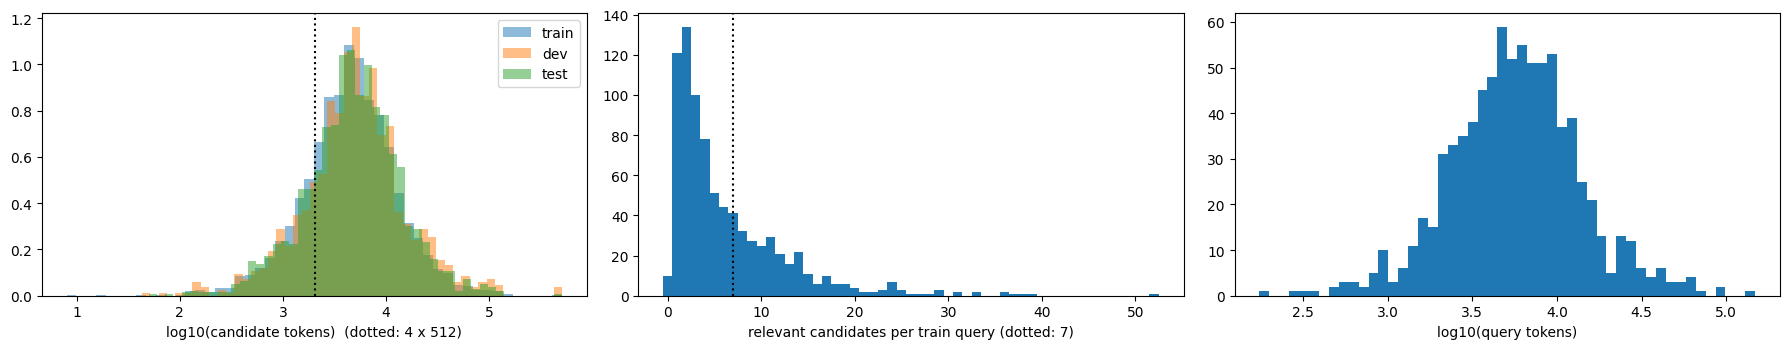

In [23]:
if RUN_EDA:
    import numpy as np, matplotlib.pyplot as plt, pandas as pd
    D.describe_raw(DATA_DIR)
    ST = D.stats(DATA)
    print(json.dumps(ST, indent=1))
    YA = {s: year_analysis(DATA, s) for s in ("train", "dev")}
    print("year analysis:", json.dumps(YA, indent=1))
    BG = pd.DataFrame(bm25_grid(DATA, "dev"))
    print("BM25 on dev:"); display(BG)
    tr = DATA["train"]
    fig, ax = plt.subplots(1, 3, figsize=(18, 3.6))
    for s in ("train", "dev", "test"):
        ax[0].hist(np.log10([max(1, len(t)) for t in DATA[s]["c_tokens"]]), bins=50, alpha=0.5, density=True, label=s)
    ax[0].axvline(np.log10(2048), color="k", ls=":"); ax[0].set_xlabel("log10(candidate tokens)  (dotted: 4 x 512)"); ax[0].legend()
    g = [len(tr["gold"][q]) for q in tr["q_ids"]]
    ax[1].hist(g, bins=np.arange(max(g) + 2) - 0.5); ax[1].axvline(7, color="k", ls=":")
    ax[1].set_xlabel("relevant candidates per train query (dotted: 7)")
    ax[2].hist(np.log10([max(1, len(t)) for t in tr["q_tokens"]]), bins=50); ax[2].set_xlabel("log10(query tokens)")
    plt.tight_layout(); plt.show()
    json.dump({"stats": ST, "years": YA, "bm25_dev": BG.to_dict("records")}, open(f"{WORK}/data_analysis.json", "w"),
              indent=1, default=str)

## BM25 setting for hard-negative mining and fusion (best dev micro-F1@7 when `BM25_AUTO`), scores cached for all splits

In [24]:
BM25_CFG = dict(DEFAULTS["bm25"])
if BM25_AUTO:
    G = BG.to_dict("records") if RUN_EDA else bm25_grid(DATA, "dev")
    BM25_CFG = max(G, key=lambda r: r["micro_f1@7"])["params"]
BASE["bm25"] = BM25_CFG
t0 = time.time()
for s in ("train", "dev", "test"):
    bm25_cached(DATA, s, BASE)
print("BM25 setting:", BM25_CFG, f"| scores cached in {time.time() - t0:.0f}s")

BM25 setting: {'k1': 1.2, 'b': 0.75, 'ngrams': [1, 2], 'query_tf': 'sat'} | scores cached in 110s


## Build the job list

In [25]:
def run_name(n):
    return n + TAG + ("_smoke" if SMOKE_TEST else "")

def finished(name):
    return os.path.exists(os.path.join(OUT_DIR, name, "summary.json"))

JOBS = []
for name in RUN_LIST:
    cfg = json.loads(json.dumps(EXPERIMENTS[name]))
    cfg.update(run_name=run_name(name), data_dir=str(DATA_DIR), out_dir=OUT_DIR, ckpt_root=CKPT_ROOT,
               cache_dir=CACHE_DIR, max_queries=MAXQ, max_cands=MAXC)
    key = cfg["backbone"]["ckpt"].lstrip("@")
    if key not in FOUND:
        print(f"SKIP {name}: checkpoint @{key} not attached"); continue
    cfg["backbone"]["ckpt"] = FOUND[key]
    teacher = None
    if cfg.get("kd", {}).get("teacher_run"):
        teacher = run_name(os.path.basename(cfg["kd"]["teacher_run"]))
        cfg["kd"]["teacher_run"] = os.path.join(OUT_DIR, teacher)
        if teacher not in [run_name(n) for n in RUN_LIST] and not finished(teacher):
            print(f"SKIP {name}: teacher {teacher} is neither in RUN_LIST nor finished earlier"); continue
    cfg["bm25"] = dict(BM25_CFG)
    cfg.setdefault("train", {})["max_minutes"] = MAX_MINUTES
    for k, v in OVERRIDES.items():
        set_by_path(cfg, k, json.dumps(v))
    if SMOKE_TEST:
        cfg["backbone"]["keep_layers"] = 1 if not cfg["backbone"].get("keep_layers") else 2
        cfg["train"].update(epochs=min(1, cfg["train"].get("epochs", 1)), max_minutes=5, batch_queries=4)
        cfg["chunks"] = {**cfg.get("chunks", {}), "len": 128, "k": 2, "train_k": 1}
    if SKIP_FINISHED and finished(cfg["run_name"]):
        print(f"  {cfg['run_name']:26s} already finished -> skipped (SKIP_FINISHED)"); continue
    JOBS.append((cfg["run_name"], cfg, teacher))
for n, c, t in JOBS:
    m = merge(DEFAULTS, c)
    print(f"  {n:26s} model {os.path.basename(os.path.dirname(c['backbone']['ckpt'])):22s} layers "
          f"{c['backbone'].get('keep_layers') or 'all':4} method {m['method']['name']:8s} rep {m['rep']['pool']}/"
          f"{m['rep']['sim']:6s} loss {m['loss']['name']:8s} negatives {m['neg']['miner']}" + (f"  (teacher {t})" if t else ""))

  T1_A2_full                 model A_llama_decoder_v2     layers all  method full     rep mean/cos    loss infonce  negatives bm25
  R2_B_full                  model B_encoder_decoder      layers all  method full     rep mean/cos    loss infonce  negatives bm25
  R1_A2_lorma                model A_llama_decoder_v2     layers all  method lorma    rep mean/cos    loss infonce  negatives bm25
  R3_C_partial               model C_hybrid_prefix_mlm    layers all  method partial  rep mean/cos    loss infonce  negatives bm25
  R4_KD_D6_from_T1           model D_efficient_swa_mqa    layers    6 method full     rep mean/cos    loss infonce  negatives bm25  (teacher T1_A2_full)
  X0_A2_frozen               model A_llama_decoder_v2     layers all  method frozen   rep mean/cos    loss infonce  negatives bm25
  X0_B_frozen                model B_encoder_decoder      layers all  method frozen   rep mean/cos    loss infonce  negatives bm25
  X1_D6_noKD                 model D_efficient_swa_mqa    lay

## Run (parallel on 2 GPUs, otherwise sequential)

In [26]:
import time, traceback
os.makedirs(f"{OUT_DIR}/_jobs", exist_ok=True); os.makedirs(f"{OUT_DIR}/_logs", exist_ok=True)
KEEP = ("[epoch]", "[submit]", "[kd]", "[train]", "[model]", "[dev]", "[neg]", "[data]", "early stop", "Error", "Traceback")

def run_parallel(jobs, gpus):
    pending, running, done, failed = list(jobs), {}, set(), set()
    t0 = time.time()
    while pending or running:
        for g in gpus:
            if g in running:
                continue
            for j in list(pending):
                name, cfg, teacher = j
                if teacher and teacher in failed:
                    print(f"SKIP {name}: teacher {teacher} failed"); pending.remove(j); failed.add(name); continue
                if teacher and not finished(teacher):
                    continue
                path = f"{OUT_DIR}/_jobs/{name}.json"
                json.dump(cfg, open(path, "w"), indent=1)
                log = open(f"{OUT_DIR}/_logs/{name}.log", "w")
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g), PYTHONUNBUFFERED="1")
                proc = subprocess.Popen([sys.executable, "-u", "-m", "p7pcr.run", "--config", path],
                                        cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[g] = (name, proc, log, 0)
                pending.remove(j)
                print(f"[{time.time()-t0:6.0f}s] START {name} on GPU {g}")
                break
        time.sleep(15)
        for g, (name, proc, log, pos) in list(running.items()):
            txt = open(f"{OUT_DIR}/_logs/{name}.log").read()
            for line in txt[pos:].splitlines():
                if any(k in line for k in KEEP):
                    print(f"  [{name} @GPU{g}] {line}")
            running[g] = (name, proc, log, len(txt))
            if proc.poll() is not None:
                log.close(); del running[g]
                if proc.returncode == 0 and finished(name):
                    done.add(name); print(f"[{time.time()-t0:6.0f}s] DONE  {name}")
                else:
                    failed.add(name); print(f"[{time.time()-t0:6.0f}s] FAILED {name} (exit {proc.returncode}); log tail:")
                    print("\n".join(txt.splitlines()[-25:]))
        if pending and not running and all(t and not finished(t) for _, _, t in pending):
            for n, _, t in pending:
                print(f"SKIP {n}: teacher {t} never finished")
            break
    return done, failed

if PARALLEL and N_GPU >= 2:
    DONE, FAILED = run_parallel(JOBS, list(range(N_GPU)))
else:
    DONE, FAILED = set(), set()
    for name, cfg, teacher in JOBS:
        if teacher and not finished(teacher):
            print(f"SKIP {name}: teacher {teacher} not finished"); continue
        print(f"\n##################### {name} #####################")
        try:
            summary, model = run(cfg, data=DATA); del model; torch.cuda.empty_cache(); DONE.add(name)
        except Exception:
            traceback.print_exc(); FAILED.add(name)
            print(f">>> {name} FAILED; continuing")

os.makedirs(f"{WORK}/submissions", exist_ok=True)
for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
    s = json.load(open(p))
    if s["run"].endswith("_smoke") or not s.get("submission") or "params_total" not in s:
        continue
    shutil.copy(s["submission"], f"{WORK}/submissions/{s['run']}.zip")
print("done:", sorted(DONE), "| failed:", sorted(FAILED))
print("submissions:", sorted(os.listdir(f"{WORK}/submissions")))

[     0s] START T1_A2_full on GPU 0
[     0s] START R2_B_full on GPU 1
  [T1_A2_full @GPU0] [data] train 827 queries / 4320 candidates | dev 118 / 1023 | test 237 / 1727
  [T1_A2_full @GPU0] [model] arch A (LlamaLM) | layers 11/11 | attention bidirectional | method full | chunks 4x512 uniform (train 2) | rep mean/mean/cos proj 256
  [T1_A2_full @GPU0] [model] params total 94.00M | trainable 93.996M (100.0%)
  [T1_A2_full @GPU0] [train] 5308 (query, relevant) instances from 827 queries | pool 4320 | 4 epochs x 5308 | 664 steps/epoch | batch 8 queries + 3 hard negatives each (bm25) | in-batch True | loss infonce | amp torch.float16
  [R2_B_full @GPU1] [data] train 827 queries / 4320 candidates | dev 118 / 1023 | test 237 / 1727
  [R2_B_full @GPU1] [model] arch B (EncDecLM) | layers 6/6 | attention bidirectional | method full | chunks 4x512 uniform (train 2) | rep mean/mean/cos proj 256
  [R2_B_full @GPU1] [model] params total 42.47M | trainable 42.475M (100.0%)
  [R2_B_full @GPU1] [train

## Results table (also saved as `/kaggle/working/RESULTS.csv`)

In [27]:
import pandas as pd, numpy as np
rows = []
for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
    s = json.load(open(p))
    if "params_total" not in s or SMOKE_TEST != s["run"].endswith("_smoke"):
        continue
    d, d0 = s["dev"], s["dev_before"]
    rows.append({"run": s["run"], "arch": s["arch"], "method": s["method"]["name"] + ("+KD" if s.get("kd_teacher") else ""),
                 "layers": s["layers"], "rep": f"{s['rep']['pool']}/{s['rep']['agg']}/{s['rep']['sim']}",
                 "loss": s["loss"] if s["epochs_run"] else "- (no training)",
                 "negatives": "-" if not s["epochs_run"] else s["neg"]["miner"] if s["neg"]["n_hard"] else "in-batch", "params_M": round(s["params_total"] / 1e6, 1),
                 "trainable_M": round(s["params_trainable"] / 1e6, 3), "trainable_%": s["trainable_pct"],
                 "train_min": s["train_minutes"], "best_epoch": s["best_epoch"], "peak_mem_GB": round(s["peak_train_mem_gb"] or 0, 2),
                 "docs_per_s": s["docs_per_sec"], "F1@7_0": round(d0["micro_f1@7"], 4), "F1@7": round(d["micro_f1@7"], 4),
                 "P@7": round(d["micro_p@7"], 4), "R@7": round(d["micro_r@7"], 4), "R@20": round(d["recall@20"], 4),
                 "R@100": round(d["recall@100"], 4), "MRR": round(d["mrr"], 4)})
dv = DATA["dev"]
brep, _, _ = report(bm25_cached(DATA, "dev", BASE), dv["q_ids"], dv["c_ids"], dv["gold"])
BM25_ROW = {"run": "BM25 (lexical baseline)", "F1@7": round(brep["micro_f1@7"], 4), "P@7": round(brep["micro_p@7"], 4),
            "R@7": round(brep["micro_r@7"], 4), "R@20": round(brep["recall@20"], 4), "R@100": round(brep["recall@100"], 4),
            "MRR": round(brep["mrr"], 4)}
RES = pd.DataFrame(rows)
if rows:
    RES = RES.sort_values("F1@7", ascending=False).reset_index(drop=True)
    RES.to_csv(f"{WORK}/RESULTS.csv", index=False)
    pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250)
    display(pd.concat([RES, pd.DataFrame([BM25_ROW])], ignore_index=True))
else:
    print("no finished runs")

,run,arch,method,layers,rep,loss,negatives,params_M,trainable_M,trainable_%,train_min,best_epoch,peak_mem_GB,docs_per_s,F1@7_0,F1@7,P@7,R@7,R@20,R@100,MRR
0,X7_A2_maxsim,A,full,11.0,attn/attn/maxsim,infonce,bm25,94.0,93.997,100.000,41.2,2.0,3.31,33.4,0.2301,0.3257,0.3547,0.3011,0.4676,0.6629,0.6209
1,R3_C_partial,C,partial,10.0,mean/mean/cos,infonce,bm25,70.2,19.994,28.473,40.9,4.0,1.58,45.0,0.2557,0.3202,0.3487,0.2960,0.4717,0.6978,0.6981
2,X8_A2_ance,A,full,11.0,mean/mean/cos,multipos,model,94.0,93.996,100.000,41.3,2.0,3.24,30.4,0.2557,0.3146,0.3426,0.2909,0.4728,0.6865,0.6602
3,X2_A2_qlora,A,qlora,11.0,mean/mean/cos,infonce,bm25,96.1,2.314,2.408,41.6,2.0,2.34,24.5,0.2490,0.3113,0.3390,0.2878,0.4769,0.6814,0.6575
4,T1_A2_full,A,full,11.0,mean/mean/cos,infonce,bm25,94.0,93.996,100.000,41.3,2.0,3.24,33.1,0.2557,0.3079,0.3354,0.2847,0.4687,0.6906,0.6885
5,X3_A2_prefix,A,prefix,11.0,mean/mean/cos,infonce,bm25,94.1,0.332,0.352,41.3,2.0,2.31,29.1,0.2702,0.3035,0.3305,0.2806,0.4522,0.6752,0.6669
6,R4_KD_D6_from_T1,D,full+KD,6.0,mean/mean/cos,infonce,bm25,46.0,45.965,100.000,40.6,2.0,1.92,72.8,0.2190,0.3035,0.3305,0.2806,0.4512,0.6978,0.6569
7,X5_A2_inbatch,A,full,11.0,mean/mean/cos,infonce,in-batch,94.0,93.996,100.000,41.2,4.0,2.01,33.4,0.2557,0.2890,0.3148,0.2672,0.4594,0.6917,0.6229
8,R1_A2_lorma,A,lorma,11.0,mean/mean/cos,infonce,bm25,96.4,2.630,2.727,41.6,2.0,2.52,24.2,0.2457,0.2846,0.3099,0.2631,0.4368,0.6670,0.6401
9,X1_D6_noKD,D,full,6.0,mean/mean/cos,infonce,bm25,46.0,45.965,100.000,40.7,4.0,1.89,69.7,0.2268,0.2824,0.3075,0.2610,0.4296,0.6465,0.5980


## Training curves (dev micro-F1@7 and recall@100 per epoch; epoch 0 = before fine-tuning)

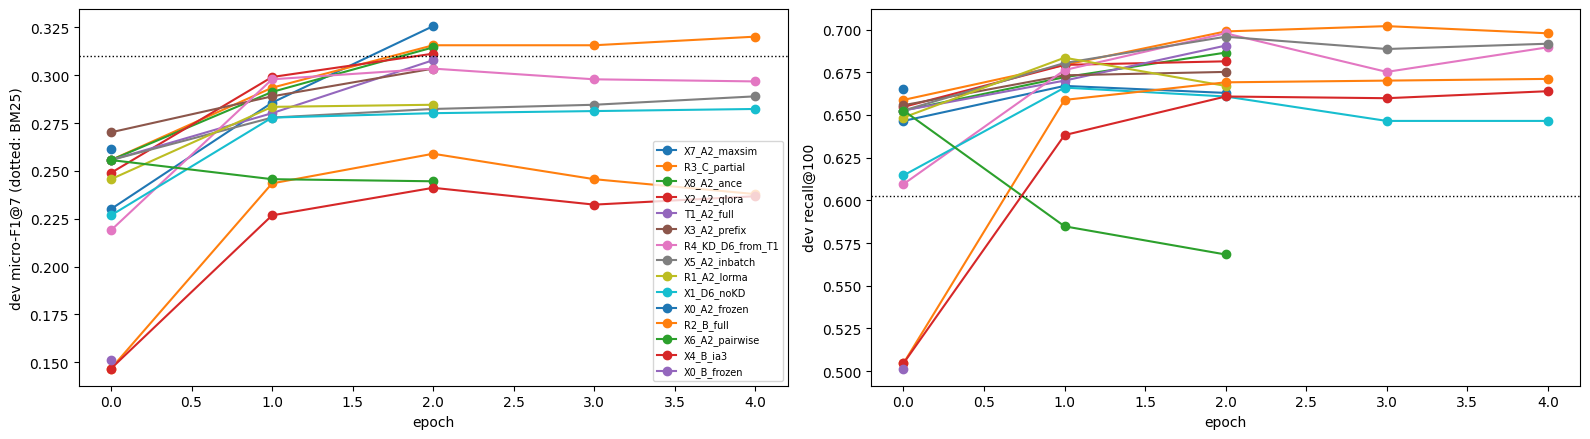

In [28]:
import matplotlib.pyplot as plt
if rows:
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
    for r in RES["run"]:
        h = json.load(open(f"{OUT_DIR}/{r}/history.json"))
        ax[0].plot([x["epoch"] for x in h], [x["micro_f1@7"] for x in h], marker="o", label=r)
        ax[1].plot([x["epoch"] for x in h], [x["recall@100"] for x in h], marker="o", label=r)
    for a in ax:
        a.axhline(BM25_ROW["F1@7"] if a is ax[0] else BM25_ROW["R@100"], color="k", ls=":", lw=1)
        a.set_xlabel("epoch")
    ax[0].set_ylabel("dev micro-F1@7 (dotted: BM25)"); ax[1].set_ylabel("dev recall@100")
    ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## Fusion → two more submissions

In [29]:
FUS = {}
if rows:
    dense = [r for r in RES["run"] if "frozen" not in r]
    best = dense[0] if FUSION_RUN == "auto" else run_name(FUSION_RUN)
    members = dense[:3] if ENSEMBLE == "auto" else [run_name(n) for n in ENSEMBLE]
    for name, mem in ((f"HYB{TAG}", [best]), (f"ENS{TAG}", members)):
        if not mem or (name.startswith("ENS") and len(mem) < 2):
            continue
        name += "_smoke" if SMOKE_TEST else ""
        FUS[name] = fusion([f"{OUT_DIR}/{m}" for m in mem], DATA, BASE, f"{OUT_DIR}/{name}")
        g = pd.DataFrame(FUS[name]["grid"]).pivot(index="bm25_weight", columns="year_filter", values="micro_f1@7")
        print(name, "members", mem); display(g)
        if not SMOKE_TEST:
            shutil.copy(FUS[name]["submission"], f"{WORK}/submissions/{name}.zip")
    print({k: (v["bm25_weight"], v["year_filter"], round(v["dev"]["micro_f1@7"], 4)) for k, v in FUS.items()})

[fusion] ['X7_A2_maxsim'] | BM25 weight 0.4 | year filter False | dev micro-F1@7 0.3813
HYB members ['X7_A2_maxsim']


year_filter,False,True
bm25_weight,,
0.0,0.3257,0.3202
0.1,0.3569,0.3457
0.2,0.3691,0.3569
0.3,0.3758,0.3646
0.4,0.3813,0.3669
0.5,0.3735,0.3635
0.6,0.3658,0.3591
0.7,0.3513,0.3580


[fusion] ['X7_A2_maxsim', 'R3_C_partial', 'X8_A2_ance'] | BM25 weight 0.3 | year filter False | dev micro-F1@7 0.3880
ENS members ['X7_A2_maxsim', 'R3_C_partial', 'X8_A2_ance']


year_filter,False,True
bm25_weight,,
0.0,0.3391,0.3246
0.1,0.3669,0.3502
0.2,0.3791,0.3680
0.3,0.3880,0.3735
0.4,0.3880,0.3791
0.5,0.3780,0.3680
0.6,0.3635,0.3635
0.7,0.3569,0.3569


{'HYB': (0.4, False, 0.3813), 'ENS': (0.3, False, 0.388)}


## Long documents: which part of a case, and how many chunks? (chunk views at inference, analysis run)

In [30]:
AN = None
if rows:
    AN = [r for r in RES["run"] if "frozen" not in r][0] if ANALYSIS_RUN == "auto" else run_name(ANALYSIS_RUN)
    print("analysis run:", AN)
    V = {"trained view": {}}
    for st in ("head", "tail", "headtail", "uniform"):
        V[f"{st} 4x512"] = {"strategy": st}
    for k in (1, 2, 8):
        V[f"uniform {k}x512"] = {"strategy": "uniform", "k": k}
    if SMOKE_TEST:
        V = {k: {**v, "len": 128} if v else v for k, v in list(V.items())[:4]}
    VR = pd.DataFrame(view_ablation(f"{OUT_DIR}/{AN}", DATA, V, "cuda" if N_GPU else "cpu"))
    display(VR)
    json.dump(VR.to_dict("records"), open(f"{OUT_DIR}/{AN}/chunk_views.json", "w"), indent=1)

analysis run: X7_A2_maxsim
[views] trained view: micro-F1@7 0.3257 | recall@100 0.6629
[views] head 4x512: micro-F1@7 0.2568 | recall@100 0.6752
[views] tail 4x512: micro-F1@7 0.2913 | recall@100 0.6578
[views] headtail 4x512: micro-F1@7 0.2968 | recall@100 0.6701
[views] uniform 4x512: micro-F1@7 0.3257 | recall@100 0.6629
[views] uniform 1x512: micro-F1@7 0.2046 | recall@100 0.5982
[views] uniform 2x512: micro-F1@7 0.2613 | recall@100 0.6454
[views] uniform 8x512: micro-F1@7 0.3157 | recall@100 0.7040


,view,micro_f1@7,recall@20,recall@100,mrr
0,trained view,0.3257,0.4676,0.6629,0.6209
1,head 4x512,0.2568,0.4347,0.6752,0.5772
2,tail 4x512,0.2913,0.4275,0.6578,0.6692
3,headtail 4x512,0.2968,0.4409,0.6701,0.6301
4,uniform 4x512,0.3257,0.4676,0.6629,0.6209
5,uniform 1x512,0.2046,0.3628,0.5982,0.4960
6,uniform 2x512,0.2613,0.4121,0.6454,0.5802
7,uniform 8x512,0.3157,0.4841,0.7040,0.6813


## Retrieval errors and failure patterns (analysis run)

In [31]:
if AN:
    EA = error_analysis(f"{OUT_DIR}/{AN}", DATA, BASE)
    for k in ("f1_by_n_relevant", "f1_by_query_tokens"):
        print(k); display(pd.DataFrame(EA[k]))
    print(json.dumps({k: v for k, v in EA.items() if not k.startswith("f1_by")}, indent=1, default=str))
    json.dump(EA, open(f"{OUT_DIR}/{AN}/error_analysis.json", "w"), indent=1, default=str)

f1_by_n_relevant


,range,queries,mean_f1@7
0,1-3,33,0.1734
1,3-6,30,0.3314
2,6-10,25,0.4414
3,10-20,21,0.4477
4,20-inf,9,0.2146


f1_by_query_tokens


,range,queries,mean_f1@7
0,0-2000,10,0.1503
1,2000-5000,40,0.3022
2,5000-10000,38,0.4115
3,10000-20000,18,0.2941
4,20000-inf,12,0.2926


{
 "queries_with_no_hit": 20,
 "queries": 118,
 "gold_rank_quantiles": {
  "10": 2,
  "25": 6,
  "50": 26,
  "75": 158,
  "90": 503
 },
 "share_gold_beyond_rank_100": 0.3371,
 "median_bm25_rank": {
  "false_positives": 101.0,
  "missed_gold": 105.5,
  "retrieved_gold": 6.0
 },
 "hub_candidates(top7 of most queries)": [
  [
   "1609169",
   5
  ],
  [
   "1620184",
   4
  ],
  [
   "1057686",
   4
  ],
  [
   "568978",
   4
  ],
  [
   "957191",
   4
  ],
  [
   "317935",
   4
  ],
  [
   "791231",
   3
  ],
  [
   "201545",
   3
  ]
 ],
 "hub_share_of_top7": 0.0448
}


## Comparisons for §13.5

In [32]:
if rows:
    cols = ["run", "arch", "method", "rep", "loss", "negatives", "trainable_%", "F1@7_0", "F1@7", "R@100", "MRR"]
    pick = lambda names: RES[RES["run"].isin([run_name(n) for n in names])][cols]
    print("techniques:"); display(pick(["T1_A2_full", "R1_A2_lorma", "X2_A2_qlora", "X3_A2_prefix", "R2_B_full", "X4_B_ia3", "R3_C_partial"]))
    print("Phase-1 transfer:"); display(pick(["X0_A2_frozen", "X0_B_frozen", "T1_A2_full", "R2_B_full"]))
    print("negatives / objective / representation (all A_v2 full fine-tuning):")
    display(pick(["T1_A2_full", "X5_A2_inbatch", "X8_A2_ance", "X6_A2_pairwise", "X7_A2_maxsim", "Y2_A2_headtail", "Y5_A2_causal_last"]))

techniques:


,run,arch,method,rep,loss,negatives,trainable_%,F1@7_0,F1@7,R@100,MRR
1,R3_C_partial,C,partial,mean/mean/cos,infonce,bm25,28.473,0.2557,0.3202,0.6978,0.6981
3,X2_A2_qlora,A,qlora,mean/mean/cos,infonce,bm25,2.408,0.2490,0.3113,0.6814,0.6575
4,T1_A2_full,A,full,mean/mean/cos,infonce,bm25,100.000,0.2557,0.3079,0.6906,0.6885
5,X3_A2_prefix,A,prefix,mean/mean/cos,infonce,bm25,0.352,0.2702,0.3035,0.6752,0.6669
8,R1_A2_lorma,A,lorma,mean/mean/cos,infonce,bm25,2.727,0.2457,0.2846,0.6670,0.6401
11,R2_B_full,B,full,mean/mean/cos,infonce,bm25,100.000,0.1467,0.2590,0.6691,0.5676
13,X4_B_ia3,B,ia3,mean/mean/cos,infonce,bm25,0.393,0.1467,0.2412,0.6608,0.5516


Phase-1 transfer:


,run,arch,method,rep,loss,negatives,trainable_%,F1@7_0,F1@7,R@100,MRR
4,T1_A2_full,A,full,mean/mean/cos,infonce,bm25,100.0,0.2557,0.3079,0.6906,0.6885
10,X0_A2_frozen,A,frozen,mean/mean/cos,- (no training),-,0.0,0.2613,0.2613,0.6650,0.6088
11,R2_B_full,B,full,mean/mean/cos,infonce,bm25,100.0,0.1467,0.2590,0.6691,0.5676
14,X0_B_frozen,B,frozen,mean/mean/cos,- (no training),-,0.0,0.1512,0.1512,0.5015,0.4351


negatives / objective / representation (all A_v2 full fine-tuning):


,run,arch,method,rep,loss,negatives,trainable_%,F1@7_0,F1@7,R@100,MRR
0,X7_A2_maxsim,A,full,attn/attn/maxsim,infonce,bm25,100.0,0.2301,0.3257,0.6629,0.6209
2,X8_A2_ance,A,full,mean/mean/cos,multipos,model,100.0,0.2557,0.3146,0.6865,0.6602
4,T1_A2_full,A,full,mean/mean/cos,infonce,bm25,100.0,0.2557,0.3079,0.6906,0.6885
7,X5_A2_inbatch,A,full,mean/mean/cos,infonce,in-batch,100.0,0.2557,0.2890,0.6917,0.6229
12,X6_A2_pairwise,A,full,mean/mean/cos,pairwise,bm25,100.0,0.2557,0.2557,0.6526,0.6025


## Knowledge distillation and efficiency: model size, memory and inference cost

In [33]:
if rows:
    E = RES[["run", "arch", "method", "layers", "params_M", "trainable_M", "trainable_%", "peak_mem_GB", "train_min",
             "docs_per_s", "F1@7"]].copy()
    E["vs_best"] = (E["F1@7"] - E["F1@7"].max()).round(4)
    display(E.sort_values("params_M"))
    display(RES[RES["run"].isin([run_name(n) for n in ("T1_A2_full", "R4_KD_D6_from_T1", "X1_D6_noKD")])]
            [["run", "params_M", "peak_mem_GB", "train_min", "docs_per_s", "F1@7", "R@100", "MRR"]])

,run,arch,method,layers,params_M,trainable_M,trainable_%,peak_mem_GB,train_min,docs_per_s,F1@7,vs_best
14,X0_B_frozen,B,frozen,6,42.3,0.000,0.000,0.51,0.2,75.8,0.1512,-0.1745
11,R2_B_full,B,full,6,42.5,42.475,100.000,1.70,40.6,76.9,0.2590,-0.0667
13,X4_B_ia3,B,ia3,6,42.5,0.167,0.393,1.29,40.5,70.9,0.2412,-0.0845
6,R4_KD_D6_from_T1,D,full+KD,6,46.0,45.965,100.000,1.92,40.6,72.8,0.3035,-0.0222
9,X1_D6_noKD,D,full,6,46.0,45.965,100.000,1.89,40.7,69.7,0.2824,-0.0433
1,R3_C_partial,C,partial,10,70.2,19.994,28.473,1.58,40.9,45.0,0.3202,-0.0055
10,X0_A2_frozen,A,frozen,11,93.8,0.000,0.000,0.82,0.6,30.3,0.2613,-0.0644
2,X8_A2_ance,A,full,11,94.0,93.996,100.000,3.24,41.3,30.4,0.3146,-0.0111
0,X7_A2_maxsim,A,full,11,94.0,93.997,100.000,3.31,41.2,33.4,0.3257,0.0000
12,X6_A2_pairwise,A,full,11,94.0,93.996,100.000,3.24,41.3,30.3,0.2557,-0.0700


,run,params_M,peak_mem_GB,train_min,docs_per_s,F1@7,R@100,MRR
4,T1_A2_full,94.0,3.24,41.3,33.1,0.3079,0.6906,0.6885
6,R4_KD_D6_from_T1,46.0,1.92,40.6,72.8,0.3035,0.6978,0.6569
9,X1_D6_noKD,46.0,1.89,40.7,69.7,0.2824,0.6465,0.5980


## Download / submit